In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)



import os, gc, cv2, math, copy, random, zipfile
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from collections import defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

import timm
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score,
                             confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

CLASS_NAMES  = ["no_dr", "mild", "moderate", "severe", "proliferative_dr"]
num_classes  = len(CLASS_NAMES)
FOLDER_NAMES = {0:"No_DR", 1:"Mild", 2:"Moderate", 3:"Severe", 4:"Proliferate_DR"}
CLASS_MAP    = {"No_DR":0, "Mild":1, "Moderate":2, "Severe":3, "Proliferate_DR":4}

STAGE2_SIZE  = 512
STAGE3_SIZE  = 384
BATCH        = 16
BATCH_CLF    = 16

STAGE1_W     = "/content/drive/MyDrive/DR_Project/stage1/weights/stage1_original_fixed_best_dr_b0.pth"
STAGE2_W     = "/content/drive/MyDrive/DR_Project/RVS_normal_split_separate/attention_unet_best.pth"
STAGE2_THRESHOLD_FILE = "/content/drive/MyDrive/DR_Project/RVS_normal_split_separate/selected_threshold.json"
DR2015_DIR = "/content/drive/MyDrive/Dataset"
VESSEL_ROOT  = "/content/drive/MyDrive/Vessel_Merged"
VESSEL_META  = os.path.join(VESSEL_ROOT, "metadata.csv")

STAGE3_DIR   = "/content/stage3_local"
WEIGHTS_DIR  = os.path.join(STAGE3_DIR, "weights")
RESULTS_DIR  = os.path.join(STAGE3_DIR, "results")
DR_OUT_DIR   = os.path.join(STAGE3_DIR, "dr2015_structured")

STAGE3_G_W   = os.path.join(WEIGHTS_DIR, "stage3_generator_best.pth")
STAGE3_D_W   = os.path.join(WEIGHTS_DIR, "stage3_discriminator_best.pth")
STAGE3_CLF_W = os.path.join(WEIGHTS_DIR, "stage3_clf_best.pth")

for d in [WEIGHTS_DIR, RESULTS_DIR, DR_OUT_DIR]:
    os.makedirs(d, exist_ok=True)

for p in [STAGE1_W, STAGE2_W, STAGE2_THRESHOLD_FILE, VESSEL_META, DR2015_DIR]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing: {p}")
print("All paths OK.")

Mounted at /content/drive
Device: cuda
All paths OK.


In [4]:
def apply_clahe_rgb(pil_img):

    img = np.array(pil_img)

    img_bgr = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2BGR
    )

    lab = cv2.cvtColor(
        img_bgr,
        cv2.COLOR_BGR2LAB
    )

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    l2 = clahe.apply(l)

    lab2 = cv2.merge(
        [l2, a, b]
    )

    bgr2 = cv2.cvtColor(
        lab2,
        cv2.COLOR_LAB2BGR
    )

    rgb2 = cv2.cvtColor(
        bgr2,
        cv2.COLOR_BGR2RGB
    )

    return Image.fromarray(rgb2)




def img_to_tensor_rgb_clahe(
    img,
    size
):

    img = apply_clahe_rgb(
        img
    )


    img = img.resize(
        (size, size),
        Image.BILINEAR
    )

    arr = (
        np.array(img)
        .astype(np.float32)
        / 255.0
    )

    arr = np.transpose(
        arr,
        (2, 0, 1)
    )

    return torch.tensor(
        arr,
        dtype=torch.float32
    )





def img_to_tensor_rgb(
    img,
    size
):

    img = img.resize(
        (size, size),
        Image.BILINEAR
    )

    arr = (
        np.array(img)
        .astype(np.float32)
        / 255.0
    )

    arr = np.transpose(
        arr,
        (2, 0, 1)
    )

    return torch.tensor(
        arr,
        dtype=torch.float32
    )




def mask_to_tensor_1ch(
    mask,
    size
):

    mask = mask.resize(
        (size, size),
        Image.NEAREST
    )

    arr = (
        np.array(mask)
        .astype(np.float32)
    )

    arr = (
        arr > 127
    ).astype(np.float32)

    return torch.tensor(
        arr,
        dtype=torch.float32
    ).unsqueeze(0)


def chunk_list(lst, n):

    for i in range(
        0,
        len(lst),
        n
    ):

        yield lst[
            i:i+n
        ]



In [5]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class AttentionGate(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g  = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x  = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi  = nn.Sequential(nn.Conv2d(F_int,1,1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
    def forward(self, g, x):
        return x * self.psi(self.relu(self.W_g(g) + self.W_x(x)))

class AttUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=64):
        super().__init__()
        self.enc1=DoubleConv(in_ch,base);   self.pool1=nn.MaxPool2d(2)
        self.enc2=DoubleConv(base,base*2);  self.pool2=nn.MaxPool2d(2)
        self.enc3=DoubleConv(base*2,base*4);self.pool3=nn.MaxPool2d(2)
        self.enc4=DoubleConv(base*4,base*8);self.pool4=nn.MaxPool2d(2)
        self.bottleneck=DoubleConv(base*8,base*16)
        self.up4=nn.ConvTranspose2d(base*16,base*8,2,stride=2)
        self.att4=AttentionGate(base*8,base*8,base*4)
        self.dec4=DoubleConv(base*16,base*8)
        self.up3=nn.ConvTranspose2d(base*8,base*4,2,stride=2)
        self.att3=AttentionGate(base*4,base*4,base*2)
        self.dec3=DoubleConv(base*8,base*4)
        self.up2=nn.ConvTranspose2d(base*4,base*2,2,stride=2)
        self.att2=AttentionGate(base*2,base*2,base)
        self.dec2=DoubleConv(base*4,base*2)
        self.up1=nn.ConvTranspose2d(base*2,base,2,stride=2)
        self.att1=AttentionGate(base,base,base//2)
        self.dec1=DoubleConv(base*2,base)
        self.out=nn.Conv2d(base,out_ch,1)
    def forward(self, x):
        e1=self.enc1(x); e2=self.enc2(self.pool1(e1))
        e3=self.enc3(self.pool2(e2)); e4=self.enc4(self.pool3(e3))
        b=self.bottleneck(self.pool4(e4))
        d4=self.up4(b);  e4a=self.att4(d4,e4); d4=self.dec4(torch.cat([d4,e4a],1))
        d3=self.up3(d4); e3a=self.att3(d3,e3); d3=self.dec3(torch.cat([d3,e3a],1))
        d2=self.up2(d3); e2a=self.att2(d2,e2); d2=self.dec2(torch.cat([d2,e2a],1))
        d1=self.up1(d2); e1a=self.att1(d1,e1); d1=self.dec1(torch.cat([d1,e1a],1))
        return self.out(d1)


import json
with open(STAGE2_THRESHOLD_FILE, "r") as f:
    THRESHOLD_STAGE2 = float(json.load(f)["selected_threshold"])
print("Stage 2 validation-selected threshold:", THRESHOLD_STAGE2)

stage2 = AttUNet(in_ch=3, out_ch=1, base=64).to(device)
stage2.load_state_dict(torch.load(STAGE2_W, map_location=device, weights_only=True))
stage2.eval()
for p in stage2.parameters(): p.requires_grad = False
print("Stage2 loaded and ready.")

Stage 2 validation-selected threshold: 0.475
Stage2 loaded and ready.


In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class GRefinerUNet(nn.Module):
    def __init__(self, in_ch=4, out_ch=1, base=32):
        super().__init__()

        self.enc1 = ConvBlock(in_ch, base)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ConvBlock(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ConvBlock(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = ConvBlock(base * 2, base)

        self.outc = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.outc(d1)


class PatchDiscriminator(nn.Module):
    def __init__(self, in_ch=4, base=64):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_ch, base, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base, base * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(base * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base * 2, base * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(base * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base * 4, 1, 4, 1, 1)
        )

    def forward(self, x):
        return self.net(x)


G = GRefinerUNet(in_ch=4, out_ch=1, base=32).to(device)
D = PatchDiscriminator(in_ch=4, base=64).to(device)

print("GAN architecture ready.")

GAN architecture ready.


In [7]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader


dfv = pd.read_csv(
    VESSEL_META
)


if (
    "image" in dfv.columns
    and
    "mask" in dfv.columns
):

    IMG_COL = "image"
    MASK_COL = "mask"


elif (
    "img" in dfv.columns
    and
    "gt" in dfv.columns
):

    IMG_COL = "img"
    MASK_COL = "gt"


elif (
    "out_img" in dfv.columns
    and
    "out_mask" in dfv.columns
):

    IMG_COL = "out_img"
    MASK_COL = "out_mask"


else:

    raise ValueError(
        f"Unknown image/mask columns: "
        f"{list(dfv.columns)}"
    )


if "split" not in dfv.columns:

    raise ValueError(
        "metadata.csv does not contain "
        "the 'split' column."
    )




class VesselTrainDS(Dataset):

    def __init__(
        self,
        df,
        root,
        size=STAGE2_SIZE
    ):

        self.df = df.reset_index(
            drop=True
        )

        self.root = root
        self.size = size


    def __len__(self):

        return len(
            self.df
        )


    def __getitem__(
        self,
        idx
    ):

        r = self.df.iloc[idx]


        img_path = os.path.join(
            self.root,
            str(r[IMG_COL])
        )


        mask_path = os.path.join(
            self.root,
            str(r[MASK_COL])
        )



        x = img_to_tensor_rgb_clahe(

            Image.open(
                img_path
            ).convert("RGB"),

            self.size

        )


        y = mask_to_tensor_1ch(

            Image.open(
                mask_path
            ).convert("L"),

            self.size

        )


        return x, y




train_full_df = dfv[
    dfv["split"]
    .astype(str)
    .str.lower()
    ==
    "train"
].reset_index(
    drop=True
)


test_df_v = dfv[
    dfv["split"]
    .astype(str)
    .str.lower()
    ==
    "test"
].reset_index(
    drop=True
)


train_df_v, val_df_v = train_test_split(

    train_full_df,

    test_size=0.20,

    random_state=SEED,

    shuffle=True

)


train_df_v = train_df_v.reset_index(
    drop=True
)

val_df_v = val_df_v.reset_index(
    drop=True
)

test_df_v = test_df_v.reset_index(
    drop=True
)




train_ds = VesselTrainDS(
    train_df_v,
    VESSEL_ROOT,
    STAGE2_SIZE
)


val_ds = VesselTrainDS(
    val_df_v,
    VESSEL_ROOT,
    STAGE2_SIZE
)


test_ds = VesselTrainDS(
    test_df_v,
    VESSEL_ROOT,
    STAGE2_SIZE
)




train_loader_v = DataLoader(
    train_ds,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)


val_loader_v = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


test_loader_v = DataLoader(
    test_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)


print(
    "Total images      :",
    len(dfv)
)

print(
    "Training images   :",
    len(train_ds)
)

print(
    "Validation images :",
    len(val_ds)
)

print(
    "Testing images    :",
    len(test_ds)
)


Total images      : 48
Training images   : 30
Validation images : 8
Testing images    : 10


In [9]:
def quick_dice(
    pred,
    target,
    eps=1e-7
):

    pred = pred.float()
    target = target.float()

    tp = (
        (pred == 1)
        &
        (target == 1)
    ).sum().item()

    fp = (
        (pred == 1)
        &
        (target == 0)
    ).sum().item()

    fn = (
        (pred == 0)
        &
        (target == 1)
    ).sum().item()

    return (
        2 * tp + eps
    ) / (
        2 * tp
        +
        fp
        +
        fn
        +
        eps
    )


stage2 = stage2.to(
    device
).eval()


dice_scores = []


with torch.no_grad():

    for x, y in tqdm(
        test_loader_v,
        desc="Stage 2 check"
    ):

        x = x.to(device)
        y = y.to(device)


        prob = torch.sigmoid(
            stage2(x)
        )


        pred = (
            prob > 0.50
        ).float()


        dice_scores.append(
            quick_dice(
                pred,
                y
            )
        )


stage2_check_dice = float(
    np.mean(
        dice_scores
    )
)




print(
    "STAGE 2 CHECK"
)



print(
    f"Stage 2 Dice  : "
    f"{stage2_check_dice:.4f}"
)


if abs(
    stage2_check_dice - 0.7778
) > 0.01:

    raise RuntimeError(
        "Stage 2 does not match the original "
        "Stage 2 result. Do not train GAN yet."
    )


Stage 2 check:   0%|          | 0/10 [00:00<?, ?it/s]

STAGE 2 CHECK
Stage 2 Dice  : 0.7768


In [12]:

import os
import json
import numpy as np
import torch
from tqdm.auto import tqdm

S2_OUT = "/content/drive/MyDrive/DR_Project/RVS_normal_split_separate"

threshold_file = os.path.join(
    S2_OUT,
    "selected_threshold.json"
)

if not os.path.isfile(threshold_file):
    raise FileNotFoundError(
        f"S2 threshold file not found: {threshold_file}"
    )

with open(threshold_file, "r") as f:
    threshold_data = json.load(f)

if isinstance(threshold_data, dict):
    for key in ("selected_threshold", "best_threshold", "threshold"):
        if key in threshold_data:
            THRESHOLD_STAGE2 = float(threshold_data[key])
            break
    else:
        raise KeyError("Threshold key not found in S2 JSON.")
else:
    THRESHOLD_STAGE2 = float(threshold_data)

print("Original S2 threshold:", THRESHOLD_STAGE2)

stage2 = stage2.to(device).eval()

for p in stage2.parameters():
    p.requires_grad_(False)

stage2_tn = 0
stage2_fp = 0
stage2_fn = 0
stage2_tp = 0

with torch.inference_mode():
    for x, y in tqdm(
        test_loader_v,
        desc="Stage 2 consistency check"
    ):
        x = x.to(device)
        y = y.to(device)

        logits = stage2(x)
        probabilities = torch.sigmoid(logits)

        pred = probabilities >= THRESHOLD_STAGE2
        target = y >= 0.5

        if pred.shape != target.shape:
            raise ValueError(
                f"Shape mismatch: {pred.shape} vs {target.shape}"
            )

        stage2_tp += int((pred & target).sum().item())
        stage2_tn += int((~pred & ~target).sum().item())
        stage2_fp += int((pred & ~target).sum().item())
        stage2_fn += int((~pred & target).sum().item())

tp = stage2_tp
tn = stage2_tn
fp = stage2_fp
fn = stage2_fn

check_dice = 2 * tp / max(2 * tp + fp + fn, 1)
check_iou = tp / max(tp + fp + fn, 1)
check_precision = tp / max(tp + fp, 1)
check_recall = tp / max(tp + fn, 1)
check_accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)

original_metrics = {
    "Dice": 0.777804,
    "IoU": 0.636398,
    "Precision": 0.761339,
    "Recall": 0.794996,
    "Accuracy": 0.961671
}

original_counts = {
    "TN": 2345102,
    "FP": 55128,
    "FN": 45349,
    "TP": 175861
}

current_metrics = {
    "Dice": check_dice,
    "IoU": check_iou,
    "Precision": check_precision,
    "Recall": check_recall,
    "Accuracy": check_accuracy
}

current_counts = {
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp
}

print("\n" + "=" * 70)
print("STAGE 2 CONSISTENCY CHECK")
print("=" * 70)

print(
    f"{'Metric':<15}"
    f"{'Original S2':>15}"
    f"{'Current S3':>15}"
    f"{'Difference':>15}"
)

for name, value in current_metrics.items():
    original = original_metrics[name]
    difference = abs(value - original)

    print(
        f"{name:<15}"
        f"{original:>15.6f}"
        f"{value:>15.6f}"
        f"{difference:>15.6f}"
    )

print("\nCONFUSION MATRIX COUNTS")
print("-" * 70)

print(
    f"{'Count':<15}"
    f"{'Original S2':>15}"
    f"{'Current S3':>15}"
    f"{'Difference':>15}"
)

for name, value in current_counts.items():
    original = original_counts[name]

    print(
        f"{name:<15}"
        f"{original:>15,}"
        f"{value:>15,}"
        f"{value - original:>+15,}"
    )

TOLERANCE = 0.01

metrics_match = all(
    abs(current_metrics[k] - original_metrics[k]) <= TOLERANCE
    for k in original_metrics
)

counts_match = all(
    current_counts[k] == original_counts[k]
    for k in original_counts
)

print("\n" + "=" * 70)

if metrics_match and counts_match:
    print("STAGE 2 CONSISTENCY CHECK PASSED")
    print("S3 reproduces the original S2 test results.")
elif metrics_match:
    print("STAGE 2 CONSISTENCY CHECK PARTIALLY PASSED")
    print("Metrics match within tolerance, but confusion counts differ.")
    print("Check preprocessing, threshold, and test split.")
else:
    print("STAGE 2 CONSISTENCY CHECK FAILED")
    print("Check model weights, preprocessing, threshold, and test split.")

print("=" * 70)


Original S2 threshold: 0.475


Stage 2 consistency check:   0%|          | 0/10 [00:00<?, ?it/s]


STAGE 2 CONSISTENCY CHECK
Metric             Original S2     Current S3     Difference
Dice                  0.777804       0.777804       0.000000
IoU                   0.636398       0.636398       0.000000
Precision             0.761339       0.761339       0.000000
Recall                0.794996       0.794996       0.000000
Accuracy              0.961671       0.961671       0.000000

CONFUSION MATRIX COUNTS
----------------------------------------------------------------------
Count              Original S2     Current S3     Difference
TN                   2,345,102      2,345,102             +0
FP                      55,128         55,128             +0
FN                      45,349         45,349             +0
TP                     175,861        175,861             +0

STAGE 2 CONSISTENCY CHECK PASSED
S3 reproduces the original S2 test results.


In [13]:
bce_logits = nn.BCEWithLogitsLoss()


def dice_loss_from_logits(logits, target, eps=1e-7):
    p = torch.sigmoid(logits)

    inter = (p * target).sum(dim=(1, 2, 3))
    denom = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))

    dice = (2 * inter + eps) / (denom + eps)

    return 1.0 - dice.mean()


def sobel_edges(x):
    kx = torch.tensor(
        [[-1, 0, 1],
         [-2, 0, 2],
         [-1, 0, 1]],
        dtype=x.dtype,
        device=x.device
    ).view(1, 1, 3, 3)

    ky = torch.tensor(
        [[-1, -2, -1],
         [0, 0, 0],
         [1, 2, 1]],
        dtype=x.dtype,
        device=x.device
    ).view(1, 1, 3, 3)

    gx = F.conv2d(x, kx, padding=1)
    gy = F.conv2d(x, ky, padding=1)

    return torch.sqrt(gx ** 2 + gy ** 2 + 1e-6)


def edge_loss_from_logits(logits, target):
    pred = torch.sigmoid(logits)
    return F.l1_loss(sobel_edges(pred), sobel_edges(target))



def corrupt_coarse_mask(v_prob, y=None):


    coarse = v_prob.clone()


    if np.random.rand() < 0.50:
        fp_noise = (torch.rand_like(coarse) > 0.995).float()
        coarse = torch.clamp(coarse + fp_noise * 0.35, 0, 1)


    if np.random.rand() < 0.50:
        drop = (torch.rand_like(coarse) > 0.985).float()
        coarse = coarse * (1.0 - drop)

    if y is not None:

        if np.random.rand() < 0.50:
            false_area = (y < 0.5).float()
            fp = (torch.rand_like(coarse) > 0.997).float() * false_area
            coarse = torch.clamp(coarse + fp * 0.50, 0, 1)


        if np.random.rand() < 0.50:
            vessel_area = (y > 0.5).float()
            fn = (torch.rand_like(coarse) > 0.985).float() * vessel_area
            coarse = coarse * (1.0 - fn)

    return coarse



GAN TRAINING


GAN 1/100:   0%|          | 0/30 [00:00<?, ?it/s]


Epoch 1/100
D Loss        : 0.6286
G Loss        : 1.3263
GAN Loss      : 0.9506
Training Loss : 1.2978
Validation Loss: 1.3951
Val Dice      : 0.7682
Val IoU       : 0.6240
Val Accuracy  : 0.9686
Threshold     : 0.45
Saved best GAN weights.


GAN 2/100:   0%|          | 0/30 [00:00<?, ?it/s]


Epoch 2/100
D Loss        : 0.5069
G Loss        : 1.1615
GAN Loss      : 1.2575
Training Loss : 1.1237
Validation Loss: 1.1942
Val Dice      : 0.7839
Val IoU       : 0.6452
Val Accuracy  : 0.9691
Threshold     : 0.55
Saved best GAN weights.


GAN 3/100:   0%|          | 0/30 [00:00<?, ?it/s]

... (191 outputs left out)

GAN 99/100:   0%|          | 0/30 [00:00<?, ?it/s]


Epoch 99/100
D Loss        : 0.6438
G Loss        : 0.0449
GAN Loss      : 0.9803
Training Loss : 0.0155
Validation Loss: 0.5249
Val Dice      : 0.7759
Val IoU       : 0.6342
Val Accuracy  : 0.9696
Threshold     : 0.45


GAN 100/100:   0%|          | 0/30 [00:00<?, ?it/s]


Epoch 100/100
D Loss        : 0.6347
G Loss        : 0.0453
GAN Loss      : 0.9949
Training Loss : 0.0154
Validation Loss: 0.5302
Val Dice      : 0.7781
Val IoU       : 0.6371
Val Accuracy  : 0.9696
Threshold     : 0.45


GAN TRAINING COMPLETE
Best GAN Validation Dice : 0.7839
Best Epoch               : 7
Best Threshold           : 0.50
Using validation-selected refinement threshold: 0.5


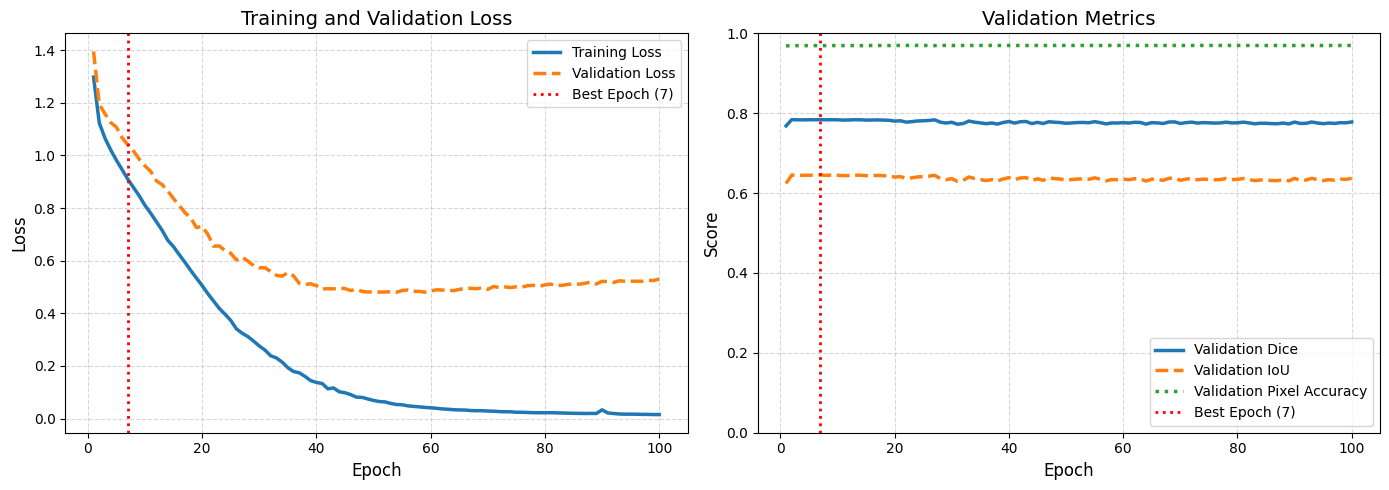

In [ ]:
import numpy as np
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
import gc

from tqdm.auto import tqdm




stage2 = stage2.to(device).eval()

for p in stage2.parameters():
    p.requires_grad = False




gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


G = GRefinerUNet(
    in_ch=4,
    out_ch=1,
    base=32
).to(device)


D = PatchDiscriminator(
    in_ch=4,
    base=64
).to(device)







optG = optim.Adam(
    G.parameters(),
    lr=2e-4,
    betas=(0.5, 0.999)
)


optD = optim.Adam(
    D.parameters(),
    lr=1e-4,
    betas=(0.5, 0.999)
)




lam_gan = 0.03

lam_edge = 0.25



EPOCHS_GAN = 100



train_losses = []

val_losses = []


val_dices = []

val_ious = []

val_accuracies = []


val_thresholds = []




best_dice = -1.0

best_thr = 0.50

best_epoch = 0




THRESHOLDS = [
    0.45,
    0.50,
    0.55,
    0.60,
    0.65
]




@torch.no_grad()
def evaluate_refiner():

    G.eval()


    validation_losses = []


    metric_store = {

        t: {

            "dice": [],
            "iou": [],
            "accuracy": []

        }

        for t in THRESHOLDS

    }




    for x, y in val_loader_v:

        x = x.to(device)

        y = y.to(device)



        stage2_prob = torch.sigmoid(
            stage2(x)
        )




        logits = G(

            torch.cat(
                [
                    x,
                    stage2_prob
                ],
                dim=1
            )

        )




        seg_loss = (

            bce_logits(
                logits,
                y
            )

            +

            dice_loss_from_logits(
                logits,
                y
            )

            +

            lam_edge
            *
            edge_loss_from_logits(
                logits,
                y
            )

        )


        validation_losses.append(
            seg_loss.item()
        )


        probability = torch.sigmoid(
            logits
        )



        for threshold in THRESHOLDS:

            pred = (
                probability
                >
                threshold
            ).float()




            tp = (
                pred * y
            ).sum(
                dim=(1, 2, 3)
            )


            fp = (
                pred
                *
                (1 - y)
            ).sum(
                dim=(1, 2, 3)
            )


            fn = (
                (1 - pred)
                *
                y
            ).sum(
                dim=(1, 2, 3)
            )


            tn = (
                (1 - pred)
                *
                (1 - y)
            ).sum(
                dim=(1, 2, 3)
            )


            eps = 1e-7


            # ------------------------------------------------
            # DICE
            # ------------------------------------------------

            dice = (
                2 * tp + eps
            ) / (
                2 * tp
                +
                fp
                +
                fn
                +
                eps
            )


            # ------------------------------------------------
            # IoU
            # ------------------------------------------------

            iou = (
                tp + eps
            ) / (
                tp
                +
                fp
                +
                fn
                +
                eps
            )


            # ------------------------------------------------
            # PIXEL ACCURACY
            # ------------------------------------------------

            accuracy = (
                tp
                +
                tn
                +
                eps
            ) / (
                tp
                +
                tn
                +
                fp
                +
                fn
                +
                eps
            )


            metric_store[
                threshold
            ]["dice"].extend(

                dice
                .detach()
                .cpu()
                .tolist()

            )


            metric_store[
                threshold
            ]["iou"].extend(

                iou
                .detach()
                .cpu()
                .tolist()

            )


            metric_store[
                threshold
            ]["accuracy"].extend(

                accuracy
                .detach()
                .cpu()
                .tolist()

            )



    mean_metrics = {}


    for threshold in THRESHOLDS:

        mean_metrics[
            threshold
        ] = {


            "dice": float(

                np.mean(

                    metric_store[
                        threshold
                    ]["dice"]

                )

            ),


            "iou": float(

                np.mean(

                    metric_store[
                        threshold
                    ]["iou"]

                )

            ),


            "accuracy": float(

                np.mean(

                    metric_store[
                        threshold
                    ]["accuracy"]

                )

            )

        }


    mean_val_loss = float(

        np.mean(
            validation_losses
        )

    )


    return (
        mean_val_loss,
        mean_metrics
    )



print("\n")
print("=" * 60)

print(
    "GAN TRAINING"
)

print("=" * 60)


for epoch in range(
    1,
    EPOCHS_GAN + 1
):



    G.train()

    D.train()


    ep_d = 0.0

    ep_g = 0.0

    ep_gan = 0.0

    ep_seg = 0.0


    nb = 0




    for x, y in tqdm(

        train_loader_v,

        desc=f"GAN {epoch}/{EPOCHS_GAN}"

    ):


        x = x.to(device)

        y = y.to(device)




        with torch.no_grad():

            v_prob = torch.sigmoid(
                stage2(x)
            )




        coarse = corrupt_coarse_mask(
            v_prob,
            y
        )




        fake_logits = G(

            torch.cat(
                [
                    x,
                    coarse
                ],
                dim=1
            )

        )


        fake_mask = torch.sigmoid(
            fake_logits
        )



        real_pred = D(

            torch.cat(
                [
                    x,
                    y
                ],
                dim=1
            )

        )


        fake_pred = D(

            torch.cat(
                [
                    x,
                    fake_mask.detach()
                ],
                dim=1
            )

        )


        d_loss = 0.5 * (

            bce_logits(

                real_pred,

                torch.full_like(
                    real_pred,
                    0.9
                )

            )

            +

            bce_logits(

                fake_pred,

                torch.zeros_like(
                    fake_pred
                )

            )

        )


        optD.zero_grad()


        d_loss.backward()


        optD.step()



        fake_pred2 = D(

            torch.cat(
                [
                    x,
                    fake_mask
                ],
                dim=1
            )

        )



        gan_loss = bce_logits(

            fake_pred2,

            torch.ones_like(
                fake_pred2
            )

        )




        seg_loss = (

            bce_logits(
                fake_logits,
                y
            )

            +

            dice_loss_from_logits(
                fake_logits,
                y
            )

            +

            lam_edge
            *
            edge_loss_from_logits(
                fake_logits,
                y
            )

        )




        g_loss = (

            seg_loss

            +

            lam_gan
            *
            gan_loss

        )


        optG.zero_grad()


        g_loss.backward()


        optG.step()



        ep_d += d_loss.item()

        ep_g += g_loss.item()

        ep_gan += gan_loss.item()

        ep_seg += seg_loss.item()


        nb += 1



    train_loss_epoch = (
        ep_seg / nb
    )



    (
        val_loss_epoch,
        val_results
    ) = evaluate_refiner()




    best_ep_thr = max(

        THRESHOLDS,

        key=lambda t:
        val_results[t]["dice"]

    )


    vd = val_results[
        best_ep_thr
    ]["dice"]


    viou = val_results[
        best_ep_thr
    ]["iou"]


    vacc = val_results[
        best_ep_thr
    ]["accuracy"]



    train_losses.append(
        train_loss_epoch
    )


    val_losses.append(
        val_loss_epoch
    )


    val_dices.append(
        vd
    )


    val_ious.append(
        viou
    )


    val_accuracies.append(
        vacc
    )


    val_thresholds.append(
        best_ep_thr
    )




    print(
        f"\nEpoch {epoch}/{EPOCHS_GAN}"
    )


    print(
        f"D Loss        : "
        f"{ep_d / nb:.4f}"
    )


    print(
        f"G Loss        : "
        f"{ep_g / nb:.4f}"
    )


    print(
        f"GAN Loss      : "
        f"{ep_gan / nb:.4f}"
    )


    print(
        f"Training Loss : "
        f"{train_loss_epoch:.4f}"
    )


    print(
        f"Validation Loss: "
        f"{val_loss_epoch:.4f}"
    )


    print(
        f"Val Dice      : "
        f"{vd:.4f}"
    )


    print(
        f"Val IoU       : "
        f"{viou:.4f}"
    )


    print(
        f"Val Accuracy  : "
        f"{vacc:.4f}"
    )


    print(
        f"Threshold     : "
        f"{best_ep_thr:.2f}"
    )




    if vd > best_dice:


        best_dice = vd


        best_thr = best_ep_thr


        best_epoch = epoch


        torch.save(
            G.state_dict(),
            STAGE3_G_W
        )


        torch.save(
            D.state_dict(),
            STAGE3_D_W
        )


        print(
            "Saved best GAN weights."
        )

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()




print("\n")
print("=" * 60)

print(
    "GAN TRAINING COMPLETE"
)

print("=" * 60)


print(
    f"Best GAN Validation Dice : "
    f"{best_dice:.4f}"
)


print(
    f"Best Epoch               : "
    f"{best_epoch}"
)


print(
    f"Best Threshold           : "
    f"{best_thr:.2f}"
)


print("=" * 60)




BEST_THR = float(
    best_thr
)


TEST_THR = float(
    best_thr
)


print(
    "Using validation-selected "
    "refinement threshold:",
    BEST_THR
)




epochs = np.arange(
    1,
    len(train_losses) + 1
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)




axes[0].plot(
    epochs,
    train_losses,
    linewidth=2.5,
    label="Training Loss"
)


axes[0].plot(
    epochs,
    val_losses,
    linestyle="--",
    linewidth=2.5,
    label="Validation Loss"
)


axes[0].axvline(
    best_epoch,
    color="red",
    linestyle=":",
    linewidth=2,
    label=f"Best Epoch ({best_epoch})"
)


axes[0].set_title(
    "Training and Validation Loss",
    fontsize=14
)


axes[0].set_xlabel(
    "Epoch",
    fontsize=12
)


axes[0].set_ylabel(
    "Loss",
    fontsize=12
)


axes[0].grid(
    True,
    linestyle="--",
    alpha=0.5
)


axes[0].legend()



axes[1].plot(
    epochs,
    val_dices,
    linewidth=2.5,
    label="Validation Dice"
)


axes[1].plot(
    epochs,
    val_ious,
    linestyle="--",
    linewidth=2.5,
    label="Validation IoU"
)


axes[1].plot(
    epochs,
    val_accuracies,
    linestyle=":",
    linewidth=2.5,
    label="Validation Pixel Accuracy"
)


axes[1].axvline(
    best_epoch,
    color="red",
    linestyle=":",
    linewidth=2,
    label=f"Best Epoch ({best_epoch})"
)


axes[1].set_title(
    "Validation Metrics",
    fontsize=14
)


axes[1].set_xlabel(
    "Epoch",
    fontsize=12
)


axes[1].set_ylabel(
    "Score",
    fontsize=12
)


axes[1].set_ylim(
    0,
    1.0
)


axes[1].grid(
    True,
    linestyle="--",
    alpha=0.5
)


axes[1].legend(
    loc="lower right"
)


plt.tight_layout()

plt.show()


TEST RESULTS

STAGE 2
----------------------------------------------
Dice      : 0.777804
Iou       : 0.636398
Precision : 0.761339
Recall    : 0.794996
Accuracy  : 0.961671

REFINED
----------------------------------------------
Dice      : 0.780648
Iou       : 0.640215
Precision : 0.765484
Recall    : 0.796424
Accuracy  : 0.962232

STAGE 2 CONSISTENCY CHECK
PASSED: Stage 2 matches original S2 results.

STAGE 2 VS cGAN REFINED
Metric                 Stage 2        Refined     Difference
Dice                  0.777804       0.780648      +0.002844
Iou                   0.636398       0.640215      +0.003817
Precision             0.761339       0.765484      +0.004145
Recall                0.794996       0.796424      +0.001429
Accuracy              0.961671       0.962232      +0.000561


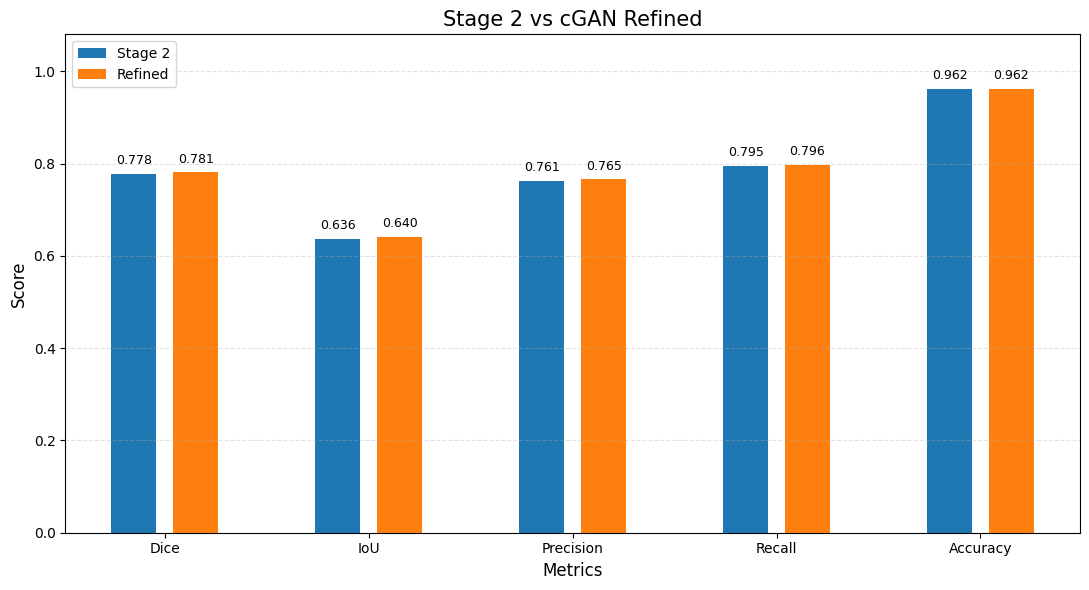

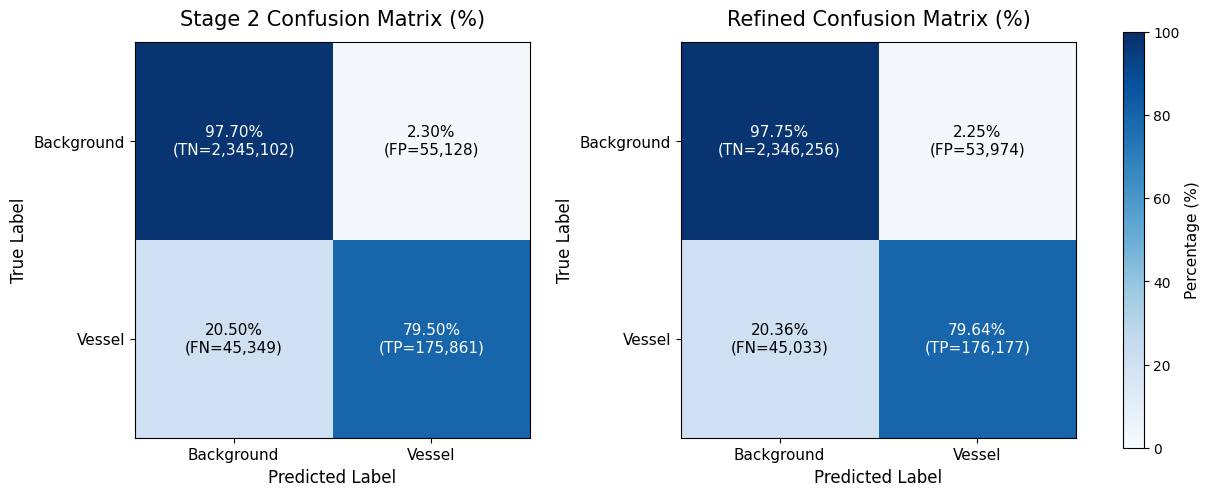

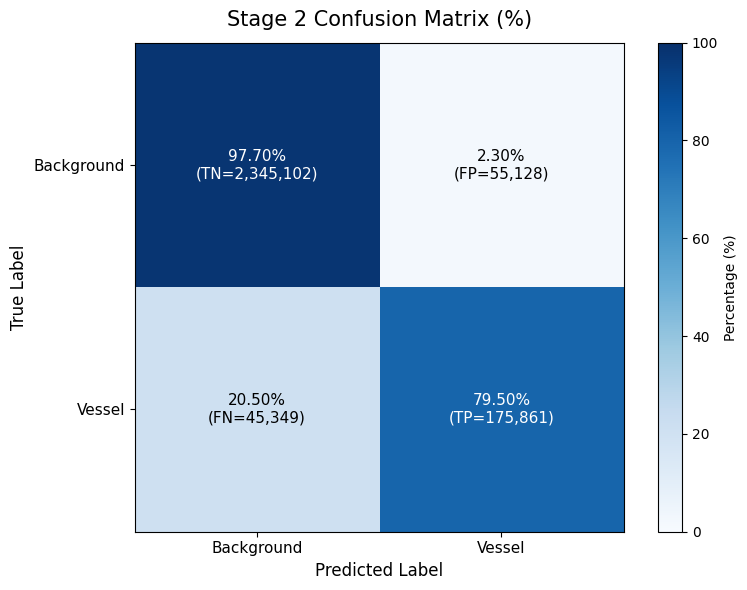

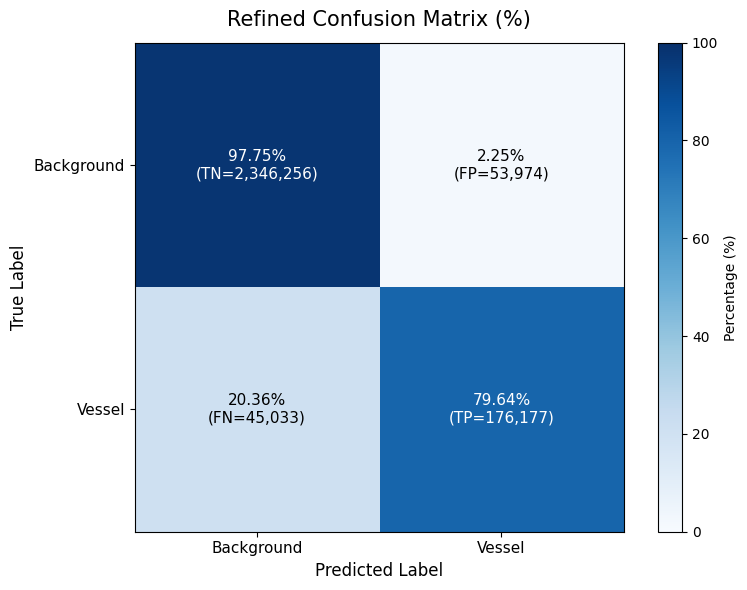


STAGE 2 CONFUSION MATRIX
True Negative  (TN): 2,345,102
False Positive (FP): 55,128
False Negative (FN): 45,349
True Positive  (TP): 175,861

REFINED CONFUSION MATRIX
True Negative  (TN): 2,346,256
False Positive (FP): 53,974
False Negative (FN): 45,033
True Positive  (TP): 176,177


In [24]:

import numpy as np
import torch
import matplotlib.pyplot as plt

THRESHOLD_STAGE2 = 0.475
TEST_THR = 0.615

G.load_state_dict(
    torch.load(
        STAGE3_G_W,
        map_location=device,
        weights_only=True
    )
)

G = G.to(device).eval()
stage2 = stage2.to(device).eval()

for p in stage2.parameters():
    p.requires_grad_(False)

for p in G.parameters():
    p.requires_grad_(False)




def calculate_metrics(pred, target, eps=1e-7):

    pred = pred.float()
    target = target.float()

    tp = ((pred == 1) & (target == 1)).sum().item()
    tn = ((pred == 0) & (target == 0)).sum().item()
    fp = ((pred == 1) & (target == 0)).sum().item()
    fn = ((pred == 0) & (target == 1)).sum().item()

    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    accuracy = (tp + tn + eps) / (tp + tn + fp + fn + eps)

    return {
        "dice": dice,
        "iou": iou,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy
    }


def confusion_counts(pred, target):

    pred = pred.float()
    target = target.float()

    tp = ((pred == 1) & (target == 1)).sum().item()
    tn = ((pred == 0) & (target == 0)).sum().item()
    fp = ((pred == 1) & (target == 0)).sum().item()
    fn = ((pred == 0) & (target == 1)).sum().item()

    return tn, fp, fn, tp


def metrics_from_counts(tn, fp, fn, tp):

    return {
        "dice": 2 * tp / max(2 * tp + fp + fn, 1),
        "iou": tp / max(tp + fp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "recall": tp / max(tp + fn, 1),
        "accuracy": (tp + tn) / max(tp + tn + fp + fn, 1)
    }


stage2_tn = 0
stage2_fp = 0
stage2_fn = 0
stage2_tp = 0

stage3_tn = 0
stage3_fp = 0
stage3_fn = 0
stage3_tp = 0

with torch.inference_mode():

    for x, y in test_loader_v:

        x = x.to(device)
        y = y.to(device)

        stage2_logits = stage2(x)

        stage2_prob = torch.sigmoid(
            stage2_logits
        )

        stage2_mask = (
            stage2_prob >= THRESHOLD_STAGE2
        ).float()

        stage3_logits = G(
            torch.cat(
                [x, stage2_prob],
                dim=1
            )
        )

        stage3_prob = torch.sigmoid(
            stage3_logits
        )

        stage3_mask = (
            stage3_prob >= TEST_THR
        ).float()

        tn, fp, fn, tp = confusion_counts(
            stage2_mask,
            y
        )

        stage2_tn += tn
        stage2_fp += fp
        stage2_fn += fn
        stage2_tp += tp

        tn, fp, fn, tp = confusion_counts(
            stage3_mask,
            y
        )

        stage3_tn += tn
        stage3_fp += fp
        stage3_fn += fn
        stage3_tp += tp


stage2_metrics = metrics_from_counts(
    stage2_tn,
    stage2_fp,
    stage2_fn,
    stage2_tp
)

refined_metrics = metrics_from_counts(
    stage3_tn,
    stage3_fp,
    stage3_fn,
    stage3_tp
)

metrics_names = [
    "dice",
    "iou",
    "precision",
    "recall",
    "accuracy"
]

print("\n" + "=" * 60)
print("TEST RESULTS")
print("=" * 60)

print("\nSTAGE 2")
print("-" * 46)

for metric in metrics_names:
    print(
        f"{metric.capitalize():10s}: "
        f"{stage2_metrics[metric]:.6f}"
    )

print("\nREFINED")
print("-" * 46)

for metric in metrics_names:
    print(
        f"{metric.capitalize():10s}: "
        f"{refined_metrics[metric]:.6f}"
    )


original_s2 = {
    "dice": 0.777804,
    "iou": 0.636398,
    "precision": 0.761339,
    "recall": 0.794996,
    "accuracy": 0.961671
}

original_counts = {
    "TN": 2345102,
    "FP": 55128,
    "FN": 45349,
    "TP": 175861
}

current_counts = {
    "TN": stage2_tn,
    "FP": stage2_fp,
    "FN": stage2_fn,
    "TP": stage2_tp
}

metrics_match = all(
    abs(stage2_metrics[k] - original_s2[k]) <= 1e-5
    for k in original_s2
)

counts_match = all(
    current_counts[k] == original_counts[k]
    for k in original_counts
)

print("\n" + "=" * 60)
print("STAGE 2 CONSISTENCY CHECK")
print("=" * 60)

if metrics_match and counts_match:
    print("PASSED: Stage 2 matches original S2 results.")
else:
    print("FAILED: Stage 2 differs from original S2 results.")

    for metric in metrics_names:
        print(
            f"{metric.capitalize():10s}: "
            f"Original={original_s2[metric]:.6f}, "
            f"Current={stage2_metrics[metric]:.6f}"
        )

    for key in original_counts:
        print(
            f"{key}: Original={original_counts[key]:,}, "
            f"Current={current_counts[key]:,}"
        )


print("\n" + "=" * 60)
print("STAGE 2 VS cGAN REFINED")
print("=" * 60)

print(
    f"{'Metric':<15}"
    f"{'Stage 2':>15}"
    f"{'Refined':>15}"
    f"{'Difference':>15}"
)

for metric in metrics_names:

    s2 = stage2_metrics[metric]
    refined = refined_metrics[metric]

    print(
        f"{metric.capitalize():<15}"
        f"{s2:>15.6f}"
        f"{refined:>15.6f}"
        f"{refined - s2:>+15.6f}"
    )


stage2_values = [
    stage2_metrics[metric]
    for metric in metrics_names
]

refined_values = [
    refined_metrics[metric]
    for metric in metrics_names
]

x_axis = np.arange(len(metrics_names)) * 1.45
width = 0.32
bar_gap = 0.12

stage2_positions = (
    x_axis - (width + bar_gap) / 2
)

refined_positions = (
    x_axis + (width + bar_gap) / 2
)

plt.figure(figsize=(11, 6))

bars_stage2 = plt.bar(
    stage2_positions,
    stage2_values,
    width,
    label="Stage 2"
)

bars_refined = plt.bar(
    refined_positions,
    refined_values,
    width,
    label="Refined"
)

plt.xlabel("Metrics", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.title(
    "Stage 2 vs cGAN Refined",
    fontsize=15
)

plt.xticks(
    x_axis,
    [
        "Dice",
        "IoU",
        "Precision",
        "Recall",
        "Accuracy"
    ]
)

plt.ylim(0, 1.08)
plt.legend()

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

for bars in [
    bars_stage2,
    bars_refined
]:

    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()


stage2_cm = np.array(
    [
        [stage2_tn, stage2_fp],
        [stage2_fn, stage2_tp]
    ],
    dtype=np.float64
)

refined_cm = np.array(
    [
        [stage3_tn, stage3_fp],
        [stage3_fn, stage3_tp]
    ],
    dtype=np.float64
)


def normalize_confusion_matrix(cm):

    row_sum = cm.sum(
        axis=1,
        keepdims=True
    )

    cm_percent = np.divide(
        cm,
        row_sum,
        out=np.zeros_like(
            cm,
            dtype=np.float64
        ),
        where=(row_sum != 0)
    )

    return cm_percent * 100


stage2_cm_percent = normalize_confusion_matrix(
    stage2_cm
)

refined_cm_percent = normalize_confusion_matrix(
    refined_cm
)


def draw_percentage_confusion_matrix(
    ax,
    cm_raw,
    cm_percent,
    title
):

    image = ax.imshow(
        cm_percent,
        cmap="Blues",
        vmin=0,
        vmax=100,
        interpolation="nearest"
    )

    ax.set_title(
        title,
        fontsize=15,
        pad=12
    )

    classes = [
        "Background",
        "Vessel"
    ]

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(
        classes,
        fontsize=11
    )

    ax.set_yticklabels(
        classes,
        fontsize=11
    )

    ax.set_xlabel(
        "Predicted Label",
        fontsize=12
    )

    ax.set_ylabel(
        "True Label",
        fontsize=12
    )

    cell_names = [
        ["TN", "FP"],
        ["FN", "TP"]
    ]

    for i in range(2):

        for j in range(2):

            percent = cm_percent[i, j]
            raw_count = int(cm_raw[i, j])

            label = (
                f"{percent:.2f}%\n"
                f"({cell_names[i][j]}={raw_count:,})"
            )

            text_color = (
                "white"
                if percent > 50
                else "black"
            )

            ax.text(
                j,
                i,
                label,
                ha="center",
                va="center",
                fontsize=11,
                color=text_color
            )

    return image


fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6),
    gridspec_kw={
        "wspace": 0.38
    }
)

im1 = draw_percentage_confusion_matrix(
    axes[0],
    stage2_cm,
    stage2_cm_percent,
    "Stage 2 Confusion Matrix (%)"
)

im2 = draw_percentage_confusion_matrix(
    axes[1],
    refined_cm,
    refined_cm_percent,
    "Refined Confusion Matrix (%)"
)

cbar = fig.colorbar(
    im2,
    ax=axes.ravel().tolist(),
    shrink=0.90,
    pad=0.04
)

cbar.set_label(
    "Percentage (%)",
    fontsize=11
)

plt.show()


fig, ax = plt.subplots(
    figsize=(8, 6)
)

im = draw_percentage_confusion_matrix(
    ax,
    stage2_cm,
    stage2_cm_percent,
    "Stage 2 Confusion Matrix (%)"
)

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Percentage (%)"
)

plt.tight_layout()
plt.show()


fig, ax = plt.subplots(
    figsize=(8, 6)
)

im = draw_percentage_confusion_matrix(
    ax,
    refined_cm,
    refined_cm_percent,
    "Refined Confusion Matrix (%)"
)

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    "Percentage (%)"
)

plt.tight_layout()
plt.show()


print("\n" + "=" * 60)
print("STAGE 2 CONFUSION MATRIX")
print("=" * 60)

print(f"True Negative  (TN): {stage2_tn:,}")
print(f"False Positive (FP): {stage2_fp:,}")
print(f"False Negative (FN): {stage2_fn:,}")
print(f"True Positive  (TP): {stage2_tp:,}")


print("\n" + "=" * 60)
print("REFINED CONFUSION MATRIX")
print("=" * 60)

print(f"True Negative  (TN): {stage3_tn:,}")
print(f"False Positive (FP): {stage3_fp:,}")
print(f"False Negative (FN): {stage3_fn:,}")
print(f"True Positive  (TP): {stage3_tp:,}")





Visualization threshold: 0.50


PREDICTIONS

Rank 1 | ID: drive_29_training
-----------------------------------------------------------------
Stage2 Prediction Score  : 0.9408
Refined Prediction Score : 0.9536
Stage2 Dice              : 0.7756
Refined Dice             : 0.7798
Stage2 IoU               : 0.6335
Refined IoU              : 0.6391
Stage2 pixels            : 23496
Refined pixels           : 22977
Added pixels             : 137
Removed pixels           : 656
Changed pixels           : 793

Rank 2 | ID: drive_35_training
-----------------------------------------------------------------
Stage2 Prediction Score  : 0.9379
Refined Prediction Score : 0.9516
Stage2 Dice              : 0.7994
Refined Dice             : 0.8013
Stage2 IoU               : 0.6659
Refined IoU              : 0.6685
Stage2 pixels            : 24989
Refined pixels           : 24423
Added pixels             : 165
Removed pixels           : 731
Changed pixels           : 896

Rank 3 | ID: drive_27_training
--

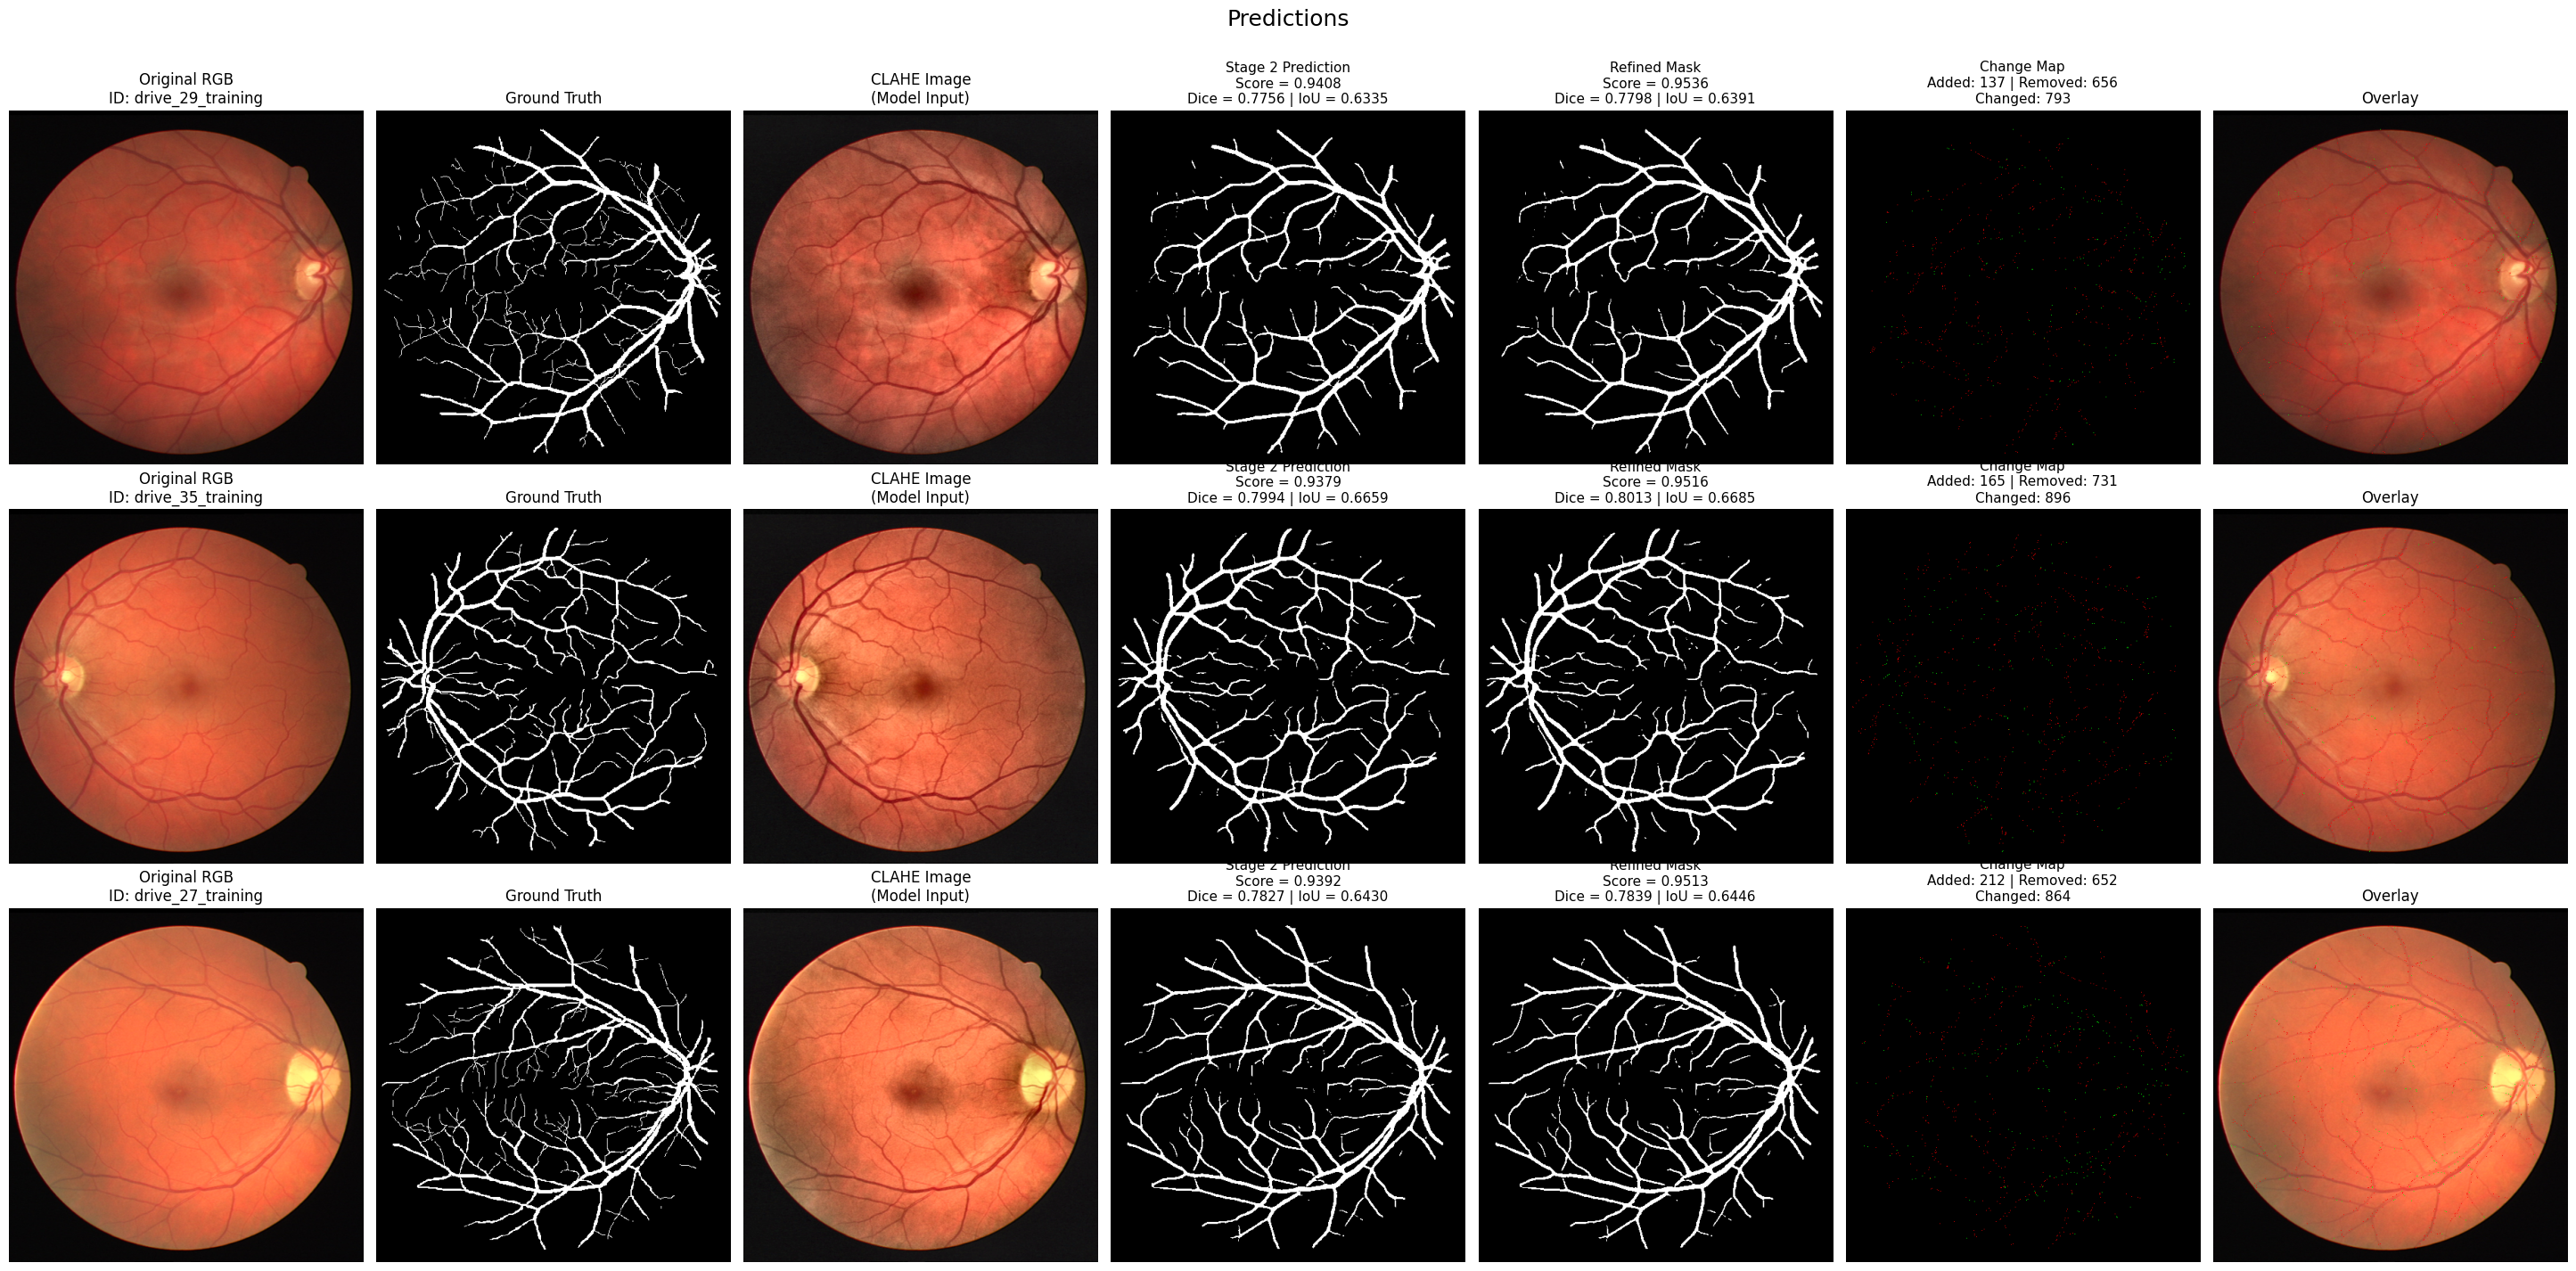

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from pathlib import Path
from PIL import Image



TEST_THR = float(best_thr)

print(
    f"Visualization threshold: {TEST_THR:.2f}"
)




def visual_dice(
    pred,
    target,
    eps=1e-7
):

    pred = pred.float()
    target = target.float()

    intersection = (
        pred * target
    ).sum()

    denominator = (
        pred.sum()
        +
        target.sum()
    )

    dice = (
        2 * intersection + eps
    ) / (
        denominator + eps
    )

    return dice.item()




def visual_iou(
    pred,
    target,
    eps=1e-7
):

    pred = pred.float()
    target = target.float()

    intersection = (
        pred * target
    ).sum()

    union = (
        pred.sum()
        +
        target.sum()
        -
        intersection
    )

    iou = (
        intersection + eps
    ) / (
        union + eps
    )

    return iou.item()



def prediction_score(
    probability,
    binary_mask
):

    vessel_pixels = (
        binary_mask > 0
    )

    if vessel_pixels.sum().item() > 0:

        score = probability[
            vessel_pixels
        ].mean()

    else:

        score = probability.mean()

    return score.item()




def resolve_original_path(
    dataset,
    idx
):

    row = dataset.df.iloc[idx]

    raw_path = Path(
        str(row[IMG_COL])
    )




    if raw_path.exists():

        return raw_path




    dataset_attributes = [
        "root",
        "root_dir",
        "data_root",
        "base_dir",
        "dataset_root",
        "img_root",
        "image_root"
    ]


    candidate_roots = []


    for attr in dataset_attributes:

        if hasattr(dataset, attr):

            value = getattr(
                dataset,
                attr
            )

            if value is not None:

                candidate_roots.append(
                    Path(value)
                )




    global_names = [
        "DATA_ROOT",
        "DATA_DIR",
        "ROOT_DIR",
        "BASE_DIR",
        "VESSEL_ROOT",
        "DATASET_ROOT",
        "CHASE_ROOT"
    ]


    for name in global_names:

        if name in globals():

            value = globals()[name]

            if value is not None:

                candidate_roots.append(
                    Path(value)
                )



    for root in candidate_roots:

        candidate = (
            root / raw_path
        )

        if candidate.exists():

            return candidate



    for root in candidate_roots:

        for parent in [
            root,
            root.parent,
            root.parent.parent
        ]:

            candidate = (
                parent / raw_path
            )

            if candidate.exists():

                return candidate


    raise FileNotFoundError(
        f"\nCould not locate original image:\n"
        f"{raw_path}\n\n"
        f"Candidate roots:\n"
        f"{candidate_roots}"
    )



def create_change_map(
    stage2_mask,
    refined_mask
):

    stage2_mask = stage2_mask.astype(
        np.uint8
    )

    refined_mask = refined_mask.astype(
        np.uint8
    )



    added = (
        (stage2_mask == 0)
        &
        (refined_mask == 1)
    )




    removed = (
        (stage2_mask == 1)
        &
        (refined_mask == 0)
    )




    change_map = np.zeros(
        (
            stage2_mask.shape[0],
            stage2_mask.shape[1],
            3
        ),
        dtype=np.float32
    )




    change_map[
        removed
    ] = [
        1.0,
        0.0,
        0.0
    ]




    change_map[
        added
    ] = [
        0.0,
        1.0,
        0.0
    ]


    return (
        change_map,
        added,
        removed
    )




def create_change_overlay(
    original_rgb,
    added,
    removed
):

    overlay = original_rgb.copy()




    overlay[
        removed
    ] = [
        1.0,
        0.0,
        0.0
    ]




    overlay[
        added
    ] = [
        0.0,
        1.0,
        0.0
    ]


    return np.clip(
        overlay,
        0,
        1
    )




def show_top_testing_predictions(
    dataset,
    number_to_show=3
):

    G.eval()
    stage2.eval()

    all_examples = []




    with torch.no_grad():

        for idx in range(
            len(dataset)
        ):




            x, y = dataset[idx]


            x = (
                x
                .unsqueeze(0)
                .to(device)
            )


            y = (
                y
                .unsqueeze(0)
                .to(device)
            )




            row = dataset.df.iloc[idx]


            raw_image_path = str(
                row[IMG_COL]
            )


            image_id = Path(
                raw_image_path
            ).stem




            image_path = resolve_original_path(
                dataset,
                idx
            )


            original_img = Image.open(
                image_path
            ).convert(
                "RGB"
            )


            original_img = original_img.resize(
                (
                    STAGE2_SIZE,
                    STAGE2_SIZE
                ),
                Image.BILINEAR
            )


            original_rgb = (
                np.array(
                    original_img
                )
                .astype(
                    np.float32
                )
                / 255.0
            )




            clahe_rgb = (
                x[0]
                .detach()
                .cpu()
                .permute(
                    1,
                    2,
                    0
                )
                .numpy()
            )


            clahe_rgb = np.clip(
                clahe_rgb,
                0,
                1
            )




            stage2_prob = torch.sigmoid(
                stage2(x)
            )


            stage2_mask = (
                stage2_prob > 0.50
            ).float()


            stage3_prob = torch.sigmoid(
                G(
                    torch.cat(
                        [
                            x,
                            stage2_prob
                        ],
                        dim=1
                    )
                )
            )


            stage3_mask = (
                stage3_prob > TEST_THR
            ).float()




            dice_s2 = visual_dice(
                stage2_mask,
                y
            )


            dice_s3 = visual_dice(
                stage3_mask,
                y
            )




            iou_s2 = visual_iou(
                stage2_mask,
                y
            )


            iou_s3 = visual_iou(
                stage3_mask,
                y
            )




            score_s2 = prediction_score(
                stage2_prob,
                stage2_mask.bool()
            )


            score_s3 = prediction_score(
                stage3_prob,
                stage3_mask.bool()
            )



            ground_truth = (
                y[
                    0,
                    0
                ]
                .detach()
                .cpu()
                .numpy()
            )




            stage2_display = (
                stage2_mask[
                    0,
                    0
                ]
                .detach()
                .cpu()
                .numpy()
            )




            stage3_display = (
                stage3_mask[
                    0,
                    0
                ]
                .detach()
                .cpu()
                .numpy()
            )


            (
                change_map,
                added,
                removed

            ) = create_change_map(
                stage2_display,
                stage3_display
            )




            overlay = create_change_overlay(
                original_rgb,
                added,
                removed
            )




            stage2_pixels = int(
                stage2_display.sum()
            )


            refined_pixels = int(
                stage3_display.sum()
            )


            added_count = int(
                added.sum()
            )


            removed_count = int(
                removed.sum()
            )


            changed_count = (
                added_count
                +
                removed_count
            )




            all_examples.append(
                {

                    "image_id":
                        image_id,

                    "original":
                        original_rgb,

                    "gt":
                        ground_truth,

                    "clahe":
                        clahe_rgb,

                    "s2":
                        stage2_display,

                    "s3":
                        stage3_display,

                    "change_map":
                        change_map,

                    "overlay":
                        overlay,

                    "dice_s2":
                        dice_s2,

                    "dice_s3":
                        dice_s3,

                    "iou_s2":
                        iou_s2,

                    "iou_s3":
                        iou_s3,

                    "score_s2":
                        score_s2,

                    "score_s3":
                        score_s3,

                    "stage2_pixels":
                        stage2_pixels,

                    "refined_pixels":
                        refined_pixels,

                    "added_count":
                        added_count,

                    "removed_count":
                        removed_count,

                    "changed_count":
                        changed_count

                }
            )




    all_examples = sorted(
        all_examples,
        key=lambda item:
            item["score_s3"],
        reverse=True
    )


    examples = all_examples[
        :number_to_show
    ]



    print("\n")
    print("=" * 75)

    print(
        "PREDICTIONS"
    )

    print("=" * 75)


    for rank, item in enumerate(
        examples,
        start=1
    ):

        print(
            f"\nRank {rank} | "
            f"ID: {item['image_id']}"
        )


        print(
            "-" * 65
        )


        print(
            f"Stage2 Prediction Score  : "
            f"{item['score_s2']:.4f}"
        )


        print(
            f"Refined Prediction Score : "
            f"{item['score_s3']:.4f}"
        )


        print(
            f"Stage2 Dice              : "
            f"{item['dice_s2']:.4f}"
        )


        print(
            f"Refined Dice             : "
            f"{item['dice_s3']:.4f}"
        )


        print(
            f"Stage2 IoU               : "
            f"{item['iou_s2']:.4f}"
        )


        print(
            f"Refined IoU              : "
            f"{item['iou_s3']:.4f}"
        )


        print(
            f"Stage2 pixels            : "
            f"{item['stage2_pixels']}"
        )


        print(
            f"Refined pixels           : "
            f"{item['refined_pixels']}"
        )


        print(
            f"Added pixels             : "
            f"{item['added_count']}"
        )


        print(
            f"Removed pixels           : "
            f"{item['removed_count']}"
        )


        print(
            f"Changed pixels           : "
            f"{item['changed_count']}"
        )




    rows = len(
        examples
    )


    fig, axes = plt.subplots(
        rows,
        7,
        figsize=(
            29,
            4.9 * rows
        )
    )


    if rows == 1:

        axes = np.expand_dims(
            axes,
            axis=0
        )


    for i, item in enumerate(
        examples
    ):




        axes[
            i,
            0
        ].imshow(
            item["original"]
        )


        axes[
            i,
            0
        ].set_title(
            f"Original RGB\n"
            f"ID: {item['image_id']}",
            fontsize=12
        )




        axes[
            i,
            1
        ].imshow(
            item["gt"],
            cmap="gray",
            vmin=0,
            vmax=1
        )


        axes[
            i,
            1
        ].set_title(
            "Ground Truth",
            fontsize=12
        )




        axes[
            i,
            2
        ].imshow(
            item["clahe"]
        )


        axes[
            i,
            2
        ].set_title(
            "CLAHE Image\n"
            "(Model Input)",
            fontsize=12
        )




        axes[
            i,
            3
        ].imshow(
            item["s2"],
            cmap="gray",
            vmin=0,
            vmax=1
        )


        axes[
            i,
            3
        ].set_title(
            f"Stage 2 Prediction\n"
            f"Score = {item['score_s2']:.4f}\n"
            f"Dice = {item['dice_s2']:.4f} | "
            f"IoU = {item['iou_s2']:.4f}",
            fontsize=11
        )



        axes[
            i,
            4
        ].imshow(
            item["s3"],
            cmap="gray",
            vmin=0,
            vmax=1
        )


        axes[
            i,
            4
        ].set_title(
            f"Refined Mask\n"
            f"Score = {item['score_s3']:.4f}\n"
            f"Dice = {item['dice_s3']:.4f} | "
            f"IoU = {item['iou_s3']:.4f}",
            fontsize=11
        )



        axes[
            i,
            5
        ].imshow(
            item["change_map"]
        )


        axes[
            i,
            5
        ].set_title(
            "Change Map\n"
            f"Added: {item['added_count']:,} | "
            f"Removed: {item['removed_count']:,}\n"
            f"Changed: {item['changed_count']:,}",
            fontsize=11
        )



        axes[
            i,
            6
        ].imshow(
            item["overlay"]
        )


        axes[
            i,
            6
        ].set_title(
            "Overlay",
            fontsize=12
        )




        for j in range(7):

            axes[
                i,
                j
            ].axis(
                "off"
            )


    plt.suptitle(
        "Predictions",
        fontsize=18
    )


    plt.tight_layout(
        rect=[
            0,
            0,
            1,
            0.97
        ]
    )


    plt.show()



show_top_testing_predictions(
    test_ds,
    number_to_show=3
)

In [ ]:
DR2015_ZIP   = "/content/drive/MyDrive/Dataset.zip"

In [ ]:
EXTRACT_DIR = "/content/drive/MyDrive/Dataset_extracted"
Path(EXTRACT_DIR).mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(DR2015_ZIP, 'r') as z:
    z.extractall(EXTRACT_DIR)
print("Extraction done:", EXTRACT_DIR)

Extraction done: /content/drive/MyDrive/Dataset_extracted


In [ ]:
DR_ROOT  = "/content/drive/MyDrive/Dataset_extracted/colored_images/colored_images"
IMG_EXTS = {".png",".jpg",".jpeg",".bmp",".tif",".tiff"}

all_imgs = []
for ext in IMG_EXTS:
    all_imgs += list(Path(DR_ROOT).rglob(f"*{ext}"))

def get_label(p):
    parent = Path(p).parent.name.strip()
    if parent in CLASS_MAP: return CLASS_MAP[parent]
    for k in CLASS_MAP:
        if k.lower() == parent.lower(): return CLASS_MAP[k]
    return -1

dr_labeled = [(str(p), get_label(str(p))) for p in all_imgs]
dr_labeled  = [(p,y) for p,y in dr_labeled if y != -1]

print("\n========== DR DATASET ==========")
print(f"Total: {len(dr_labeled)}")
cc = defaultdict(int)
for _,y in dr_labeled: cc[y] += 1
for i,n in enumerate(CLASS_NAMES):
    print(f"  {n:<22} ({FOLDER_NAMES[i]:<15}): {cc[i]:>5}")
print("=================================")


========== DR DATASET ==========
Total: 35126
  no_dr                  (No_DR          ): 25810
  mild                   (Mild           ):  2443
  moderate               (Moderate       ):  5292
  severe                 (Severe         ):   873
  proliferative_dr       (Proliferate_DR ):   708


In [ ]:
s2_dir = os.path.join(DR_OUT_DIR, "stage2_masks")
s3_dir = os.path.join(DR_OUT_DIR, "stage3_masks")
for lbl, fn in FOLDER_NAMES.items():
    os.makedirs(os.path.join(s2_dir, fn), exist_ok=True)
    os.makedirs(os.path.join(s3_dir, fn), exist_ok=True)
print("Class-wise folders created.")
for i,fn in FOLDER_NAMES.items():
    print(f"  {CLASS_NAMES[i]:<22} → stage2_masks/{fn}/  stage3_masks/{fn}/")

Class-wise folders created.
  no_dr                  → stage2_masks/No_DR/  stage3_masks/No_DR/
  mild                   → stage2_masks/Mild/  stage3_masks/Mild/
  moderate               → stage2_masks/Moderate/  stage3_masks/Moderate/
  severe                 → stage2_masks/Severe/  stage3_masks/Severe/
  proliferative_dr       → stage2_masks/Proliferate_DR/  stage3_masks/Proliferate_DR/


In [ ]:
from torch.utils.data import Dataset, DataLoader
from collections import defaultdict
from pathlib import Path
from PIL import Image
import os, gc
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

FAST_BATCH = 16
NUM_WORKERS = 4
PIN_MEMORY = True

print(f"\n==========STAGE2 VESSEL MASK PREDICTION FOR DR DATASET ==========")
print(f"Total: {len(dr_labeled)}  Batch: {FAST_BATCH}")


class DRStage2Dataset(Dataset):
    def __init__(self, items, size):
        self.items = items
        self.size = size

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img_path, label = self.items[idx]

        img = Image.open(img_path).convert("RGB")
        img = img_to_tensor_rgb_clahe(img, self.size)

        return img, int(label), str(img_path)


def collate_stage2(batch):
    imgs, labels, paths = zip(*batch)
    imgs = torch.stack(imgs, dim=0)
    labels = torch.tensor(labels, dtype=torch.long)
    return imgs, labels, list(paths)


stage2_ds = DRStage2Dataset(dr_labeled, STAGE2_SIZE)

stage2_loader = DataLoader(
    stage2_ds,
    batch_size=FAST_BATCH,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True if NUM_WORKERS > 0 else False,
    collate_fn=collate_stage2
)

stage2 = stage2.to(device).eval()

rows = []
s2_counts = defaultdict(int)

with torch.inference_mode():
    for xb, labels, paths in tqdm(stage2_loader, desc="Stage2 Prediction"):
        xb = xb.to(device, non_blocking=True)

        v_prob = torch.sigmoid(stage2(xb))
        v_mask = (v_prob > 0.5).detach().cpu().numpy().astype(np.uint8)

        labels_np = labels.numpy()

        for i, img_path in enumerate(paths):
            stem = Path(img_path).stem
            label = int(labels_np[i])
            folder = FOLDER_NAMES[label]

            p2 = os.path.join(s2_dir, folder, f"{stem}_s2.png")

            Image.fromarray(v_mask[i, 0] * 255).save(p2)

            s2_counts[label] += 1

            rows.append({
                "img_path": img_path,
                "label": label,
                "stage2_mask_path": p2,
                "stage3_mask_path": ""
            })

print(f"\nTotal: {sum(s2_counts.values())}")

for i, fn in FOLDER_NAMES.items():
    print(f"  {CLASS_NAMES[i]:<22} ({fn:<15}): {s2_counts[i]:>5}")

stage2_mask_df = pd.DataFrame(rows)
stage2_mask_csv = os.path.join(s2_dir, "stage2_mask_paths.csv")
stage2_mask_df.to_csv(stage2_mask_csv, index=False)

print(f"\nSaved CSV: {stage2_mask_csv}")


==========STAGE2 VESSEL MASK PREDICTION FOR DR DATASET ==========
Total: 35126  Batch: 16


Stage2 Prediction:   0%|          | 0/2196 [00:00<?, ?it/s]


Total: 35126
  no_dr                  (No_DR          ): 25810
  mild                   (Mild           ):  2443
  moderate               (Moderate       ):  5292
  severe                 (Severe         ):   873
  proliferative_dr       (Proliferate_DR ):   708

Saved CSV: /content/stage3_local/dr2015_structured/stage2_masks/stage2_mask_paths.csv


In [ ]:
from torch.utils.data import Dataset, DataLoader
from collections import defaultdict
from pathlib import Path
from PIL import Image

import os
import gc
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm


FAST_BATCH = 16
NUM_WORKERS = 2
PIN_MEMORY = True




BEST_THR = float(best_thr)


print(
    f"Using Stage 3 validation-selected threshold: "
    f"{BEST_THR:.2f}"
)

print(
    f"Total: {len(dr_labeled)}  "
    f"Batch: {FAST_BATCH}"
)


class DRStage3GANDataset(Dataset):

    def __init__(
        self,
        items,
        size
    ):

        self.items = items
        self.size = size


    def __len__(self):

        return len(
            self.items
        )


    def __getitem__(
        self,
        idx
    ):

        img_path, label = self.items[idx]


        img = Image.open(
            img_path
        ).convert("RGB")



        img = img_to_tensor_rgb_clahe(
            img,
            self.size
        )


        return (
            img,
            int(label),
            str(img_path)
        )


def collate_stage3_gan(batch):

    imgs, labels, paths = zip(
        *batch
    )


    imgs = torch.stack(
        imgs,
        dim=0
    )


    labels = torch.tensor(
        labels,
        dtype=torch.long
    )


    return (
        imgs,
        labels,
        list(paths)
    )



stage3_gan_ds = DRStage3GANDataset(
    dr_labeled,
    STAGE2_SIZE
)




stage3_gan_loader = DataLoader(

    stage3_gan_ds,

    batch_size=FAST_BATCH,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=PIN_MEMORY,

    persistent_workers=(
        True
        if NUM_WORKERS > 0
        else False
    ),

    collate_fn=collate_stage3_gan

)




G.load_state_dict(

    torch.load(
        STAGE3_G_W,
        map_location=device
    )

)


G = G.to(
    device
).eval()



stage2 = stage2.to(
    device
).eval()


for p in stage2.parameters():
    p.requires_grad = False




s3_counts = defaultdict(
    int
)


rows_dict = {

    Path(
        r["img_path"]
    ).stem: r

    for r in rows

}



gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()




with torch.inference_mode():


    for xb, labels, paths in tqdm(

        stage3_gan_loader,

        desc="Stage3 GAN Based Refinement"

    ):


        xb = xb.to(
            device,
            non_blocking=True
        )



        with torch.amp.autocast(

            device_type="cuda",

            enabled=torch.cuda.is_available()

        ):




            v_prob = torch.sigmoid(
                stage2(xb)
            )




            refined_prob = torch.sigmoid(

                G(

                    torch.cat(
                        [
                            xb,
                            v_prob
                        ],
                        dim=1
                    )

                )

            )




            r_mask = (

                refined_prob
                >
                BEST_THR

            ).float()



        r_mask_np = (

            r_mask
            .detach()
            .cpu()
            .numpy()
            .astype(np.uint8)

        )


        labels_np = labels.numpy()



        for i, img_path in enumerate(
            paths
        ):


            stem = Path(
                img_path
            ).stem


            label = int(
                labels_np[i]
            )


            folder = FOLDER_NAMES[
                label
            ]


            p3 = os.path.join(

                s3_dir,

                folder,

                f"{stem}_s3.png"

            )



            Image.fromarray(

                r_mask_np[
                    i,
                    0
                ]
                *
                255

            ).save(
                p3
            )




            if stem in rows_dict:

                rows_dict[
                    stem
                ][
                    "stage3_mask_path"
                ] = p3


            s3_counts[
                label
            ] += 1




print(
    f"\nStage3 refinement complete. "
    f"Total: {sum(s3_counts.values())}"
)




for i, fn in FOLDER_NAMES.items():

    print(

        f"  "
        f"{CLASS_NAMES[i]:<22} "
        f"({fn:<15}): "
        f"{s3_counts[i]:>5}"

    )



final_rows = list(
    rows_dict.values()
)


stage3_mask_df = pd.DataFrame(
    final_rows
)



stage3_mask_csv = os.path.join(

    s3_dir,

    "stage3_mask_paths.csv"

)


stage3_mask_df.to_csv(

    stage3_mask_csv,

    index=False

)


print(
    f"\nSaved CSV: "
    f"{stage3_mask_csv}"
)



gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

Using Stage 3 validation-selected threshold: 0.50
Total: 35126  Batch: 16


Stage3 GAN Based Refinement:   0%|          | 0/2196 [00:00<?, ?it/s]


Stage3 refinement complete. Total: 35126
  no_dr                  (No_DR          ): 25810
  mild                   (Mild           ):  2443
  moderate               (Moderate       ):  5292
  severe                 (Severe         ):   873
  proliferative_dr       (Proliferate_DR ):   708

Saved CSV: /content/stage3_local/dr2015_structured/stage3_masks/stage3_mask_paths.csv


In [ ]:
df_link  = pd.DataFrame(list(rows_dict.values()))
link_csv = os.path.join(DR_OUT_DIR, "dr2015_linked_stage1_stage2_stage3.csv")
df_link.to_csv(link_csv, index=False)


print(f"CSV: {link_csv}  ({len(df_link)} rows)")
print("\nStage2 masks per class:")
total=0
for i,fn in FOLDER_NAMES.items():
    c=len([f for f in os.listdir(os.path.join(s2_dir,fn)) if f.endswith(".png")])
    total+=c; print(f"  {CLASS_NAMES[i]:<22} ({fn:<15}): {c:>5}")
print(f"  TOTAL: {total}")
print("\nStage3 Refined masks per class:")
total=0
for i,fn in FOLDER_NAMES.items():
    c=len([f for f in os.listdir(os.path.join(s3_dir,fn)) if f.endswith(".png")])
    total+=c; print(f"  {CLASS_NAMES[i]:<22} ({fn:<15}): {c:>5}")
print(f"  TOTAL: {total}")

CSV: /content/stage3_local/dr2015_structured/dr2015_linked_stage1_stage2_stage3.csv  (35126 rows)

Stage2 masks per class:
  no_dr                  (No_DR          ): 25810
  mild                   (Mild           ):  2443
  moderate               (Moderate       ):  5292
  severe                 (Severe         ):   873
  proliferative_dr       (Proliferate_DR ):   708
  TOTAL: 35126

Stage3 Refined masks per class:
  no_dr                  (No_DR          ): 25810
  mild                   (Mild           ):  2443
  moderate               (Moderate       ):  5292
  severe                 (Severe         ):   873
  proliferative_dr       (Proliferate_DR ):   708
  TOTAL: 35126


In [ ]:
gc.collect()
torch.cuda.empty_cache()

Stage 3 threshold: 0.50


Class: no_dr
ID: 32888_left
------------------------------------------------------------------------
Stage2 Prediction Score  : 0.9478
Stage3 Prediction Score  : 0.9605
Stage2 pixels            : 20780
Stage3 pixels            : 20477
Added pixels             : 151
Removed pixels           : 454
Changed pixels           : 605


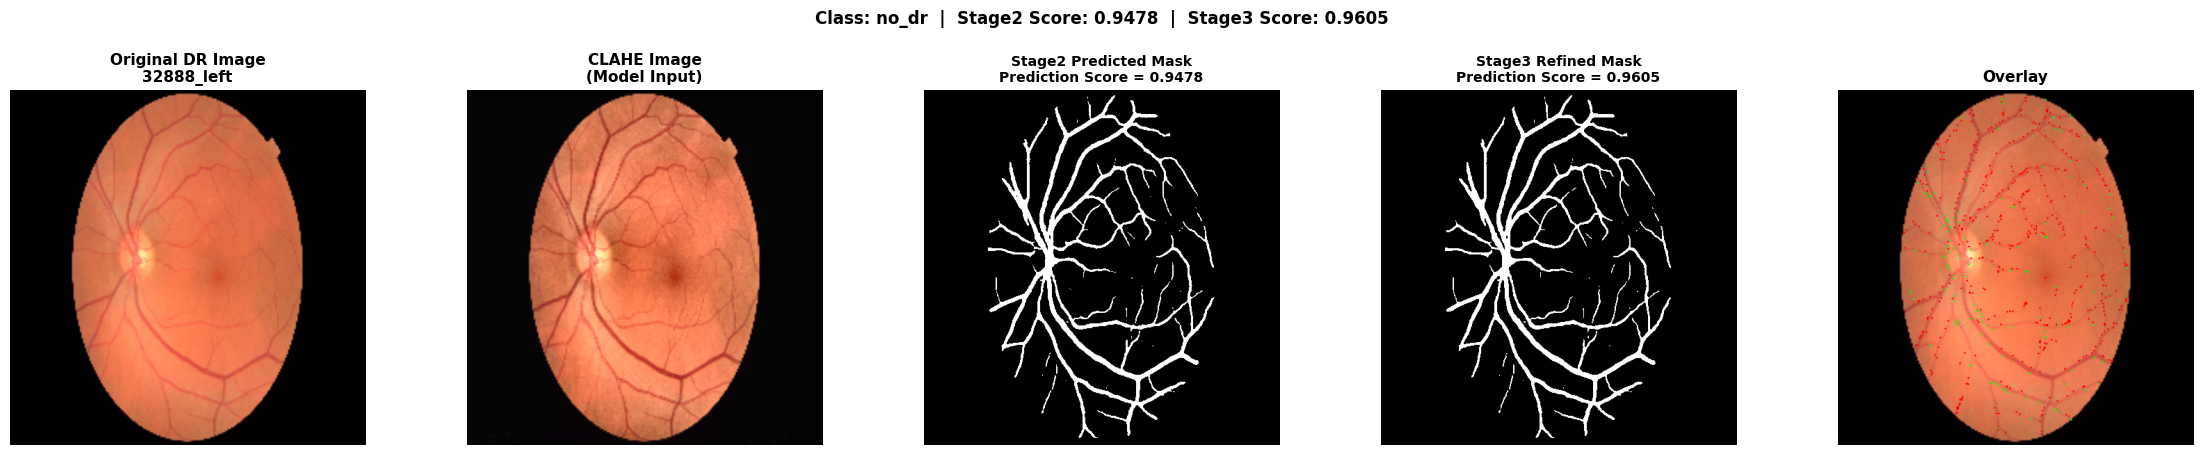



Class: mild
ID: 43683_right
------------------------------------------------------------------------
Stage2 Prediction Score  : 0.9413
Stage3 Prediction Score  : 0.9564
Stage2 pixels            : 14524
Stage3 pixels            : 14278
Added pixels             : 113
Removed pixels           : 359
Changed pixels           : 472


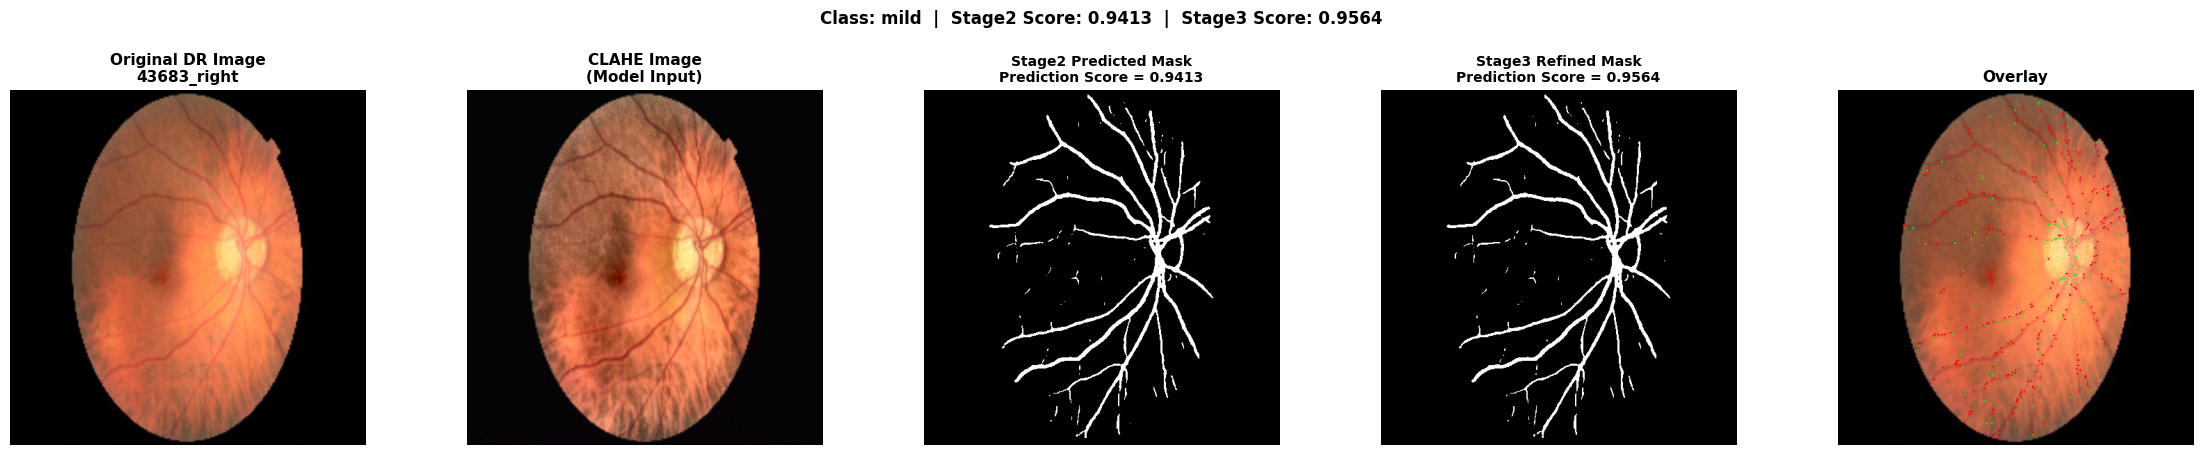



Class: moderate
ID: 31196_right
------------------------------------------------------------------------
Stage2 Prediction Score  : 0.9387
Stage3 Prediction Score  : 0.9571
Stage2 pixels            : 22504
Stage3 pixels            : 22088
Added pixels             : 171
Removed pixels           : 587
Changed pixels           : 758


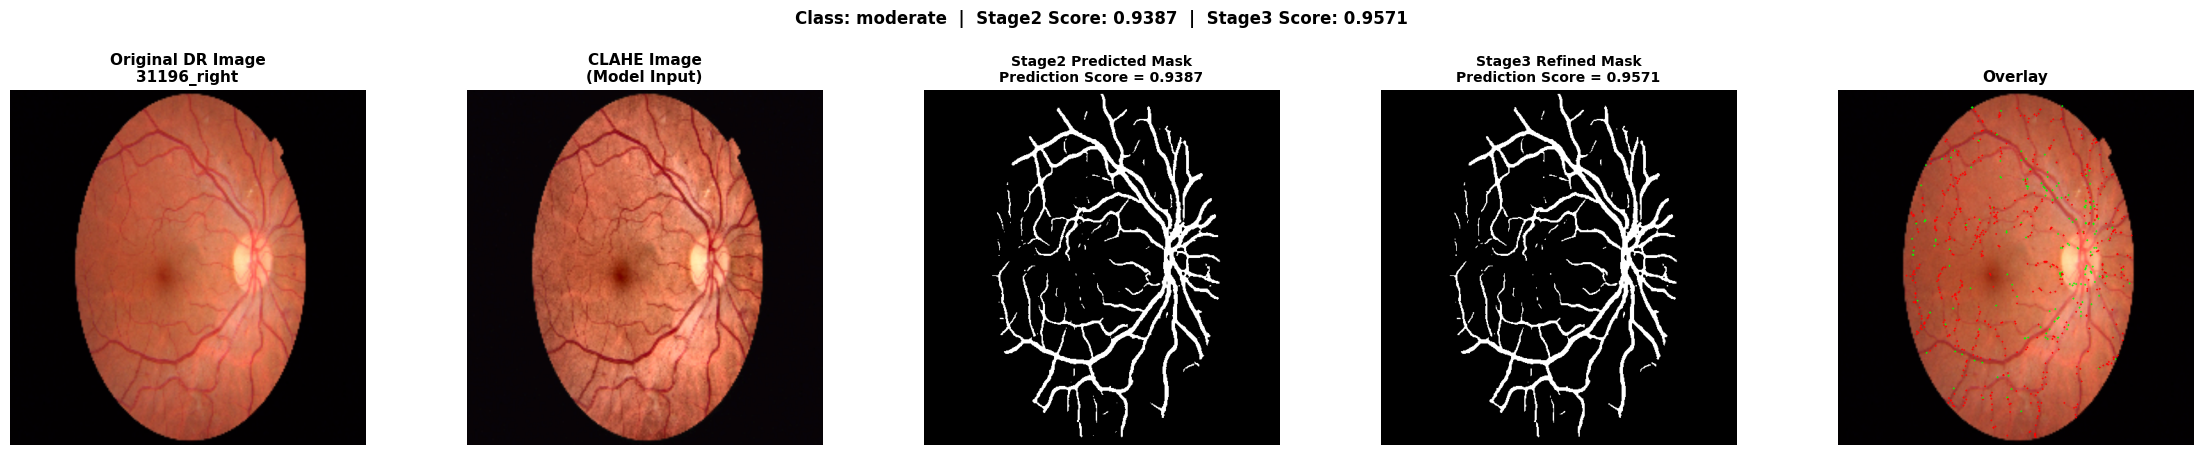



Class: severe
ID: 36692_right
------------------------------------------------------------------------
Stage2 Prediction Score  : 0.9444
Stage3 Prediction Score  : 0.9564
Stage2 pixels            : 16779
Stage3 pixels            : 16569
Added pixels             : 151
Removed pixels           : 361
Changed pixels           : 512


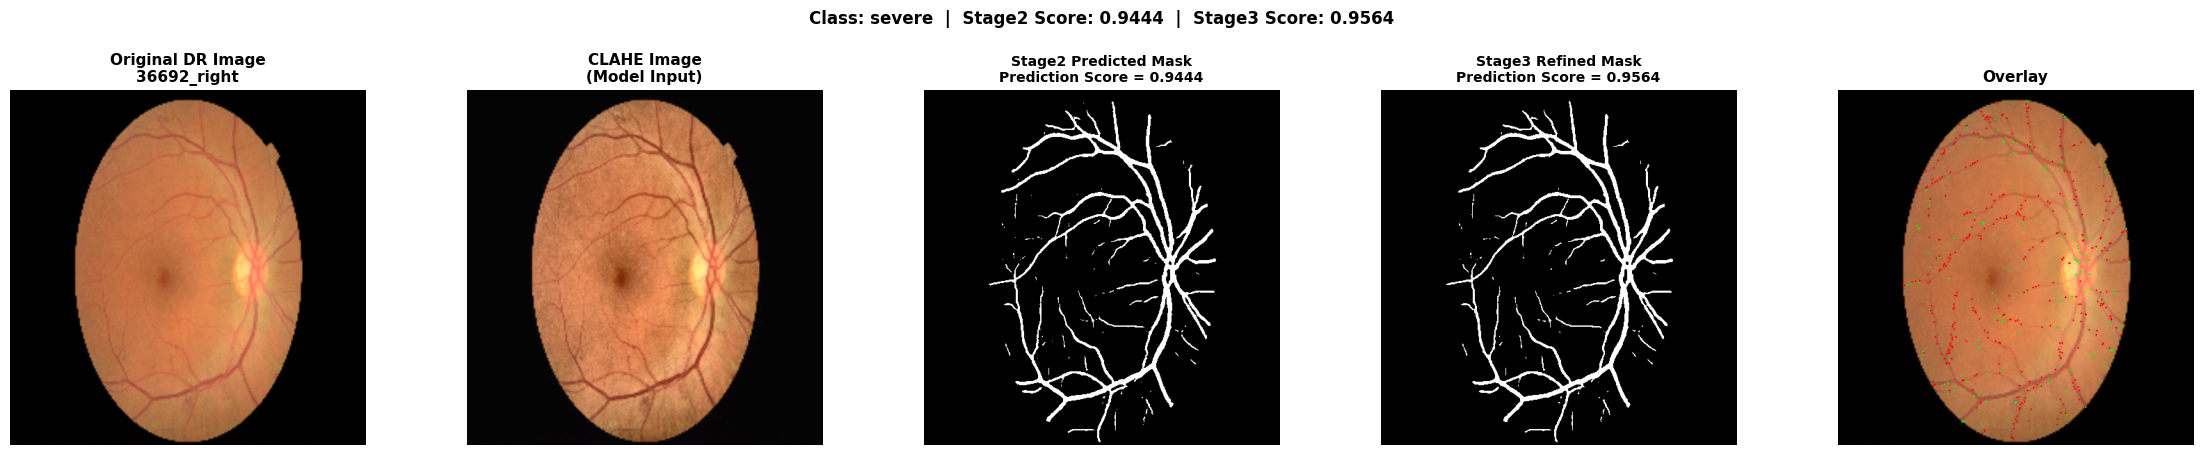



Class: proliferative_dr
ID: 13066_right
------------------------------------------------------------------------
Stage2 Prediction Score  : 0.9403
Stage3 Prediction Score  : 0.9551
Stage2 pixels            : 17504
Stage3 pixels            : 17212
Added pixels             : 134
Removed pixels           : 426
Changed pixels           : 560


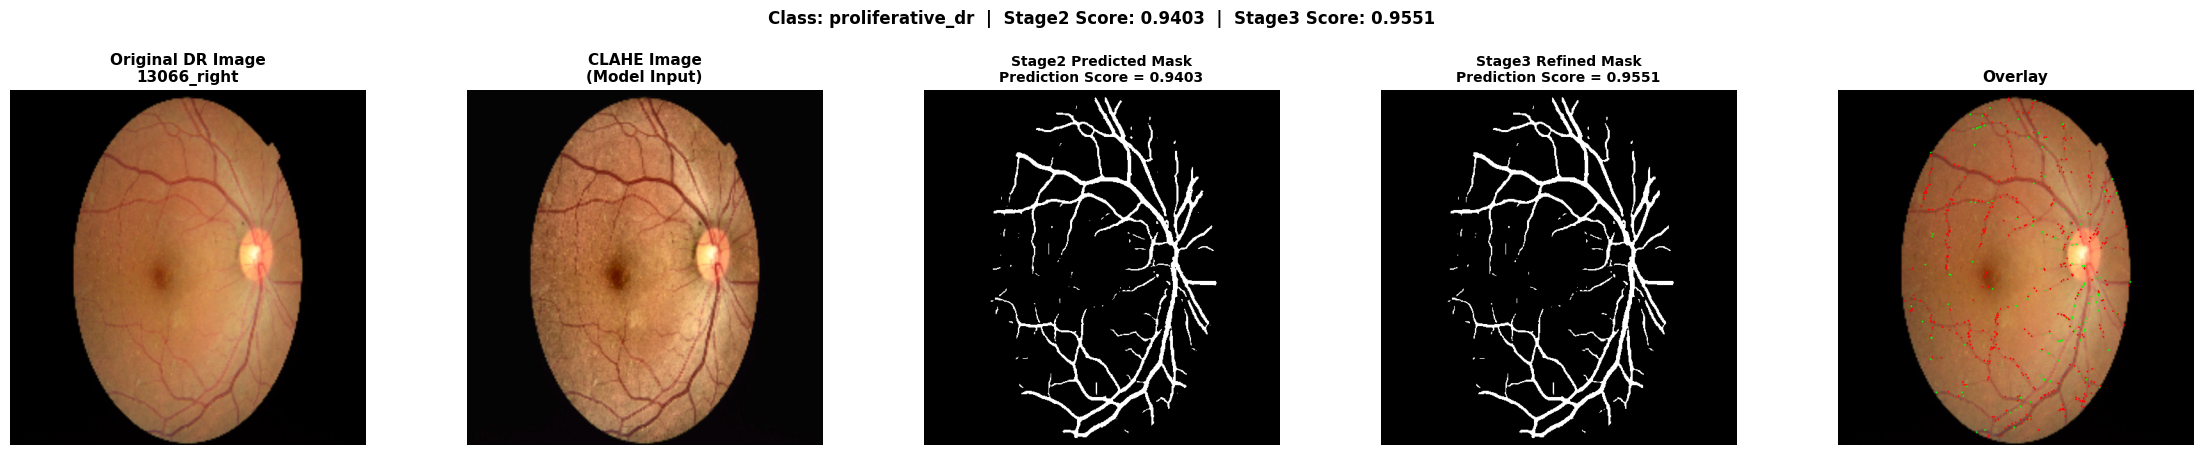


Saved CSV: /content/stage3_local/results/dr_stage2_stage3_visualization/dr_stage2_stage3_high_confidence.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from scipy.ndimage import binary_dilation
import cv2
import os
import random
import torch


OUTPUT_DIR = os.path.join(
    RESULTS_DIR,
    "dr_stage2_stage3_visualization"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

NUM_SAMPLES_PER_CLASS = 1
MAX_FILES_PER_CLASS = 1000
SCORE_CANDIDATE_POOL = 100
MIN_SHARPNESS = 12.0
OVERLAY_DILATION = 1
LATERALITY_CONFIDENCE_THRESHOLD = 0.025

BEST_THR = float(best_thr)


G.load_state_dict(
    torch.load(
        STAGE3_G_W,
        map_location=device
    )
)

G = G.to(device).eval()
stage2 = stage2.to(device).eval()

for p in stage2.parameters():
    p.requires_grad = False


print(
    f"Stage 3 threshold: {BEST_THR:.2f}"
)


MANUAL_SIDE_OVERRIDES = {
    "34492_right": "left",
}


BLACKLIST = {
    0: [
        "31136_right"
    ],
    1: [
        "29038_right","5009_left"
    ],
    2: [
        "32396_left",
        "27114_left"
    ],
    4: [
        "27395_right",
        "40893_left",
        "43339_right",
        "33725_left"
    ],
}


def _dataset_side_from_image_id(image_id):

    s = str(image_id).strip()
    low = s.lower()

    if low.endswith("_left"):
        return "left"

    if low.endswith("_right"):
        return "right"

    return None


def _image_id_root(image_id):

    s = str(image_id).strip()
    low = s.lower()

    if low.endswith("_left"):
        return s[:-5]

    if low.endswith("_right"):
        return s[:-6]

    return s


def _infer_visual_side_from_fundus(rgb_uint8, vessel_uint8):

    rgb = np.asarray(rgb_uint8, dtype=np.uint8)
    vessel = np.asarray(vessel_uint8, dtype=np.uint8)

    if rgb.ndim != 3 or rgb.shape[2] != 3:
        return None, 0.0, np.nan, np.nan

    if vessel.ndim == 3:
        vessel = cv2.cvtColor(
            vessel,
            cv2.COLOR_RGB2GRAY
        )

    h, w = rgb.shape[:2]

    if vessel.shape[:2] != (h, w):

        vessel = cv2.resize(
            vessel,
            (w, h),
            interpolation=cv2.INTER_NEAREST
        )

    lab_l = (
        cv2.cvtColor(
            rgb,
            cv2.COLOR_RGB2LAB
        )[..., 0]
        .astype(np.float32)
        / 255.0
    )

    red = (
        rgb[..., 0]
        .astype(np.float32)
        / 255.0
    )

    bright = (
        0.55 * red
        +
        0.45 * lab_l
    )

    sigma_b = max(
        4.0,
        float(w) / 30.0
    )

    bright = cv2.GaussianBlur(
        bright,
        (0, 0),
        sigmaX=sigma_b,
        sigmaY=sigma_b
    )

    vb = (
        vessel > 32
    ).astype(
        np.float32
    )

    sigma_v = max(
        5.0,
        float(w) / 24.0
    )

    vessel_density = cv2.GaussianBlur(
        vb,
        (0, 0),
        sigmaX=sigma_v,
        sigmaY=sigma_v
    )

    def _n01(a):

        a = np.asarray(
            a,
            np.float32
        )

        lo, hi = np.percentile(
            a,
            [2, 99.5]
        )

        if hi - lo < 1e-8:
            return np.zeros_like(a)

        return np.clip(
            (a - lo) / (hi - lo),
            0.0,
            1.0
        )

    score = (
        0.62 * _n01(bright)
        +
        0.38 * _n01(vessel_density)
    )

    yy0, yy1 = (
        int(0.12 * h),
        int(0.88 * h)
    )

    lx0, lx1 = (
        int(0.05 * w),
        int(0.46 * w)
    )

    rx0, rx1 = (
        int(0.54 * w),
        int(0.95 * w)
    )

    left_region = score[
        yy0:yy1,
        lx0:lx1
    ]

    right_region = score[
        yy0:yy1,
        rx0:rx1
    ]

    if (
        left_region.size == 0
        or
        right_region.size == 0
    ):
        return None, 0.0, np.nan, np.nan

    left_score = float(
        np.percentile(
            left_region,
            99.0
        )
    )

    right_score = float(
        np.percentile(
            right_region,
            99.0
        )
    )

    denom = max(
        abs(left_score)
        +
        abs(right_score),
        1e-8
    )

    confidence = float(
        abs(
            left_score
            -
            right_score
        )
        /
        denom
    )

    side = (
        "left"
        if left_score >= right_score
        else "right"
    )

    return (
        side,
        confidence,
        left_score,
        right_score
    )


def _corrected_display_image_id(
    raw_image_id,
    rgb_uint8,
    vessel_uint8,
    confidence_threshold=LATERALITY_CONFIDENCE_THRESHOLD
):

    raw = str(raw_image_id)

    dataset_side = _dataset_side_from_image_id(
        raw
    )

    (
        inferred_side,
        conf,
        left_score,
        right_score
    ) = _infer_visual_side_from_fundus(
        rgb_uint8,
        vessel_uint8
    )

    manual = MANUAL_SIDE_OVERRIDES.get(
        raw.lower()
    )

    if manual in {
        "left",
        "right"
    }:

        final_side = manual

    elif (
        inferred_side is None
        or
        conf < float(
            confidence_threshold
        )
    ):

        final_side = dataset_side

    else:

        final_side = inferred_side

    root = _image_id_root(
        raw
    )

    corrected = (
        f"{root}_{final_side}"
        if final_side in {
            "left",
            "right"
        }
        else root
    )

    return corrected


def resolve_dr_image_path(
    original_path,
    stem,
    class_idx
):

    original_path = str(
        original_path
    )

    candidates = []

    candidates.append(
        Path(original_path)
    )

    fixed_duplicate = original_path.replace(
        "/colored_images/colored_images/",
        "/colored_images/"
    )

    candidates.append(
        Path(fixed_duplicate)
    )

    fixed_duplicate_2 = original_path.replace(
        "\\colored_images\\colored_images\\",
        "\\colored_images\\"
    )

    candidates.append(
        Path(fixed_duplicate_2)
    )

    class_folder = str(
        FOLDER_NAMES[
            class_idx
        ]
    )

    class_variants = {
        class_folder,
        class_folder.lower(),
        class_folder.upper(),
        class_folder.capitalize(),
        str(CLASS_NAMES[class_idx]),
        str(CLASS_NAMES[class_idx]).lower(),
        str(CLASS_NAMES[class_idx]).capitalize()
    }

    extensions = [
        ".png",
        ".jpg",
        ".jpeg",
        ".PNG",
        ".JPG",
        ".JPEG"
    ]

    path_obj = Path(
        fixed_duplicate
    )

    possible_roots = []

    for parent in path_obj.parents:

        if parent.name.lower() == "colored_images":

            possible_roots.append(
                parent
            )

        if parent.name.lower() == "dataset_extracted":

            possible_roots.append(
                parent / "colored_images"
            )

            possible_roots.append(
                parent
                / "colored_images"
                / "colored_images"
            )

    original_obj = Path(
        original_path
    )

    for parent in original_obj.parents:

        if parent.name.lower() == "colored_images":

            possible_roots.append(
                parent
            )

        if parent.name.lower() == "dataset_extracted":

            possible_roots.append(
                parent / "colored_images"
            )

            possible_roots.append(
                parent
                / "colored_images"
                / "colored_images"
            )

    unique_roots = []

    for root in possible_roots:

        if root not in unique_roots:
            unique_roots.append(root)

    for root in unique_roots:

        for class_name in class_variants:

            for ext in extensions:

                candidates.append(
                    root
                    / class_name
                    / f"{stem}{ext}"
                )

    for candidate in candidates:

        if candidate.exists():

            return str(
                candidate
            )

    return None


def vessel_prediction_score(
    probability,
    binary_mask
):

    vessel_pixels = (
        binary_mask > 0
    )

    if vessel_pixels.sum().item() > 0:

        score = probability[
            vessel_pixels
        ].mean()

    else:

        score = probability.mean()

    return float(
        score.item()
    )


def get_dr_predictions(
    img_path
):

    original_pil = Image.open(
        img_path
    ).convert(
        "RGB"
    )

    original_rgb = np.array(
        original_pil.resize(
            (
                STAGE2_SIZE,
                STAGE2_SIZE
            ),
            Image.BILINEAR
        )
    ).astype(
        np.uint8
    )

    x_cpu = img_to_tensor_rgb_clahe(
        original_pil,
        STAGE2_SIZE
    )

    clahe_rgb = (
        x_cpu
        .detach()
        .cpu()
        .permute(
            1,
            2,
            0
        )
        .numpy()
    )

    clahe_rgb = np.clip(
        clahe_rgb,
        0.0,
        1.0
    )

    x = (
        x_cpu
        .unsqueeze(0)
        .to(device)
    )

    with torch.inference_mode():

        stage2_prob = torch.sigmoid(
            stage2(x)
        )

        stage2_mask = (
            stage2_prob > 0.50
        )

        stage3_prob = torch.sigmoid(
            G(
                torch.cat(
                    [
                        x,
                        stage2_prob
                    ],
                    dim=1
                )
            )
        )

        stage3_mask = (
            stage3_prob > BEST_THR
        )

    stage2_score = vessel_prediction_score(
        stage2_prob[
            0,
            0
        ],
        stage2_mask[
            0,
            0
        ]
    )

    stage3_score = vessel_prediction_score(
        stage3_prob[
            0,
            0
        ],
        stage3_mask[
            0,
            0
        ]
    )

    stage2_np = (
        stage2_mask[
            0,
            0
        ]
        .detach()
        .cpu()
        .numpy()
        .astype(
            np.uint8
        )
    )

    stage3_np = (
        stage3_mask[
            0,
            0
        ]
        .detach()
        .cpu()
        .numpy()
        .astype(
            np.uint8
        )
    )

    return (
        original_rgb,
        clahe_rgb,
        stage2_np,
        stage3_np,
        stage2_score,
        stage3_score
    )


def create_overlay(
    original_rgb,
    stage2_mask,
    stage3_mask
):

    added = (
        (stage2_mask == 0)
        &
        (stage3_mask == 1)
    )

    removed = (
        (stage2_mask == 1)
        &
        (stage3_mask == 0)
    )

    added_vis = binary_dilation(
        added,
        iterations=OVERLAY_DILATION
    )

    removed_vis = binary_dilation(
        removed,
        iterations=OVERLAY_DILATION
    )

    overlay = original_rgb.copy()

    overlay[
        added_vis
    ] = [
        0,
        255,
        0
    ]

    overlay[
        removed_vis
    ] = [
        255,
        0,
        0
    ]

    added_pixels = int(
        added.sum()
    )

    removed_pixels = int(
        removed.sum()
    )

    changed_pixels = (
        added_pixels
        +
        removed_pixels
    )

    return (
        overlay,
        added_pixels,
        removed_pixels,
        changed_pixels
    )


dr_lookup = {}

for original_path, label in dr_labeled:

    stem = Path(
        original_path
    ).stem

    dr_lookup[
        (
            stem,
            int(label)
        )
    ] = str(
        original_path
    )


all_output_rows = []


for class_idx, folder_name in FOLDER_NAMES.items():

    s2_folder = os.path.join(
        s2_dir,
        folder_name
    )

    s3_folder = os.path.join(
        s3_dir,
        folder_name
    )

    if (
        not os.path.exists(
            s2_folder
        )
        or
        not os.path.exists(
            s3_folder
        )
    ):

        continue

    all_files = [
        f
        for f in os.listdir(
            s2_folder
        )
        if f.endswith(
            "_s2.png"
        )
    ]

    rng = random.Random(
        20
    )

    if len(
        all_files
    ) > MAX_FILES_PER_CLASS:

        all_files = rng.sample(
            all_files,
            MAX_FILES_PER_CLASS
        )

    class_blacklist = BLACKLIST.get(
        class_idx,
        []
    )

    candidates = []
    missing_paths = 0

    for fname in all_files:

        stem = fname.replace(
            "_s2.png",
            ""
        )

        if stem in class_blacklist:
            continue

        s3_path = os.path.join(
            s3_folder,
            f"{stem}_s3.png"
        )

        if not os.path.exists(
            s3_path
        ):
            continue

        original_path = dr_lookup.get(
            (
                stem,
                int(class_idx)
            )
        )

        if original_path is None:
            continue

        img_path = resolve_dr_image_path(
            original_path,
            stem,
            class_idx
        )

        if img_path is None:

            missing_paths += 1
            continue

        try:

            original_pil = Image.open(
                img_path
            ).convert(
                "RGB"
            )

            quality_rgb = np.array(
                original_pil.resize(
                    (
                        STAGE2_SIZE,
                        STAGE2_SIZE
                    ),
                    Image.BILINEAR
                )
            )

        except Exception:

            continue

        gray = cv2.cvtColor(
            quality_rgb,
            cv2.COLOR_RGB2GRAY
        )

        h, w = gray.shape

        cy = h // 2
        cx = w // 2

        cr = min(
            h,
            w
        ) // 3

        center = gray[
            cy-cr:cy+cr,
            cx-cr:cx+cr
        ]

        gray_mean = float(
            center.mean()
        )

        gray_std = float(
            center.std()
        )

        tissue_ratio = float(
            (
                center > 25
            ).mean()
        )

        bright_ratio = float(
            (
                center > 220
            ).mean()
        )

        sharpness = float(
            cv2.Laplacian(
                center,
                cv2.CV_64F
            ).var()
        )

        if gray_mean < 30:
            continue

        if gray_mean > 220:
            continue

        if gray_std < 10:
            continue

        if tissue_ratio < 0.40:
            continue

        if bright_ratio > 0.22:
            continue

        if sharpness < MIN_SHARPNESS:
            continue

        quality_score = (
            gray_std * 2.0
            +
            tissue_ratio * 120.0
            +
            min(
                sharpness,
                500.0
            ) * 0.35
            -
            bright_ratio * 200.0
        )

        candidates.append(
            {
                "stem": stem,
                "img_path": img_path,
                "sharpness": sharpness,
                "quality_score": quality_score
            }
        )

    if len(
        candidates
    ) == 0:

        print(
            f"No valid clear image found for "
            f"{CLASS_NAMES[class_idx]}"
        )

        continue

    candidates.sort(
        key=lambda x:
            x["quality_score"],
        reverse=True
    )

    clear_pool = candidates[
        :SCORE_CANDIDATE_POOL
    ]

    scored_candidates = []

    for item in clear_pool:

        try:

            (
                original_rgb,
                clahe_rgb,
                stage2_mask,
                stage3_mask,
                stage2_score,
                stage3_score

            ) = get_dr_predictions(
                item[
                    "img_path"
                ]
            )

        except Exception:

            continue

        stage2_pixels = int(
            stage2_mask.sum()
        )

        stage3_pixels = int(
            stage3_mask.sum()
        )

        if stage2_pixels < 300:
            continue

        if stage3_pixels < 300:
            continue

        (
            overlay,
            added_pixels,
            removed_pixels,
            changed_pixels

        ) = create_overlay(
            original_rgb,
            stage2_mask,
            stage3_mask
        )

        display_stem = _corrected_display_image_id(
            item[
                "stem"
            ],
            original_rgb,
            (
                stage3_mask * 255
            ).astype(
                np.uint8
            )
        )

        item.update(
            {
                "display_stem":
                    display_stem,

                "original_rgb":
                    original_rgb,

                "clahe_rgb":
                    clahe_rgb,

                "stage2_mask":
                    stage2_mask,

                "stage3_mask":
                    stage3_mask,

                "overlay":
                    overlay,

                "stage2_score":
                    stage2_score,

                "stage3_score":
                    stage3_score,

                "stage2_pixels":
                    stage2_pixels,

                "stage3_pixels":
                    stage3_pixels,

                "added_pixels":
                    added_pixels,

                "removed_pixels":
                    removed_pixels,

                "changed_pixels":
                    changed_pixels
            }
        )

        scored_candidates.append(
            item
        )

    if len(
        scored_candidates
    ) == 0:

        print(
            f"No valid prediction found for "
            f"{CLASS_NAMES[class_idx]}"
        )

        continue

    scored_candidates.sort(
        key=lambda x: (
            x[
                "stage3_score"
            ],
            x[
                "stage2_score"
            ],
            x[
                "sharpness"
            ],
            x[
                "quality_score"
            ]
        ),
        reverse=True
    )

    best_items = scored_candidates[
        :NUM_SAMPLES_PER_CLASS
    ]

    for item in best_items:

        print("\n")
        print("=" * 72)

        print(
            f"Class: "
            f"{CLASS_NAMES[class_idx]}"
        )

        print(
            f"ID: "
            f"{item['display_stem']}"
        )

        print("-" * 72)

        print(
            f"Stage2 Prediction Score  : "
            f"{item['stage2_score']:.4f}"
        )

        print(
            f"Stage3 Prediction Score  : "
            f"{item['stage3_score']:.4f}"
        )

        print(
            f"Stage2 pixels            : "
            f"{item['stage2_pixels']}"
        )

        print(
            f"Stage3 pixels            : "
            f"{item['stage3_pixels']}"
        )

        print(
            f"Added pixels             : "
            f"{item['added_pixels']}"
        )

        print(
            f"Removed pixels           : "
            f"{item['removed_pixels']}"
        )

        print(
            f"Changed pixels           : "
            f"{item['changed_pixels']}"
        )

        print("=" * 72)


        fig, axes = plt.subplots(
            1,
            5,
            figsize=(
                23,
                4.6
            )
        )


        axes[
            0
        ].imshow(
            item[
                "original_rgb"
            ]
        )

        axes[
            0
        ].set_title(
            f"Original DR Image\n"
            f"{item['display_stem']}",
            fontweight="bold",
            fontsize=11
        )

        axes[
            0
        ].axis(
            "off"
        )


        axes[
            1
        ].imshow(
            item[
                "clahe_rgb"
            ]
        )

        axes[
            1
        ].set_title(
            "CLAHE Image\n"
            "(Model Input)",
            fontweight="bold",
            fontsize=11
        )

        axes[
            1
        ].axis(
            "off"
        )


        axes[
            2
        ].imshow(
            item[
                "stage2_mask"
            ],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[
            2
        ].set_title(
            f"Stage2 Predicted Mask\n"
            f"Prediction Score = "
            f"{item['stage2_score']:.4f}",
            fontweight="bold",
            fontsize=10
        )

        axes[
            2
        ].axis(
            "off"
        )


        axes[
            3
        ].imshow(
            item[
                "stage3_mask"
            ],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[
            3
        ].set_title(
            f"Stage3 Refined Mask\n"
            f"Prediction Score = "
            f"{item['stage3_score']:.4f}",
            fontweight="bold",
            fontsize=10
        )

        axes[
            3
        ].axis(
            "off"
        )


        axes[
            4
        ].imshow(
            item[
                "overlay"
            ]
        )

        axes[
            4
        ].set_title(
            "Overlay",
            fontweight="bold",
            fontsize=11
        )

        axes[
            4
        ].axis(
            "off"
        )


        fig.suptitle(
            f"Class: "
            f"{CLASS_NAMES[class_idx]}  |  "
            f"Stage2 Score: "
            f"{item['stage2_score']:.4f}  |  "
            f"Stage3 Score: "
            f"{item['stage3_score']:.4f}",
            fontsize=12,
            fontweight="bold"
        )


        plt.tight_layout(
            rect=[
                0,
                0,
                1,
                0.94
            ]
        )


        save_path = os.path.join(
            OUTPUT_DIR,
            f"{CLASS_NAMES[class_idx]}_"
            f"{item['display_stem']}_"
            f"stage2_stage3.png"
        )


        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

        plt.close(
            fig
        )


        all_output_rows.append(
            {
                "class_index":
                    int(class_idx),

                "class_name":
                    CLASS_NAMES[
                        class_idx
                    ],

                "image_id":
                    item[
                        "display_stem"
                    ],

                "stage2_prediction_score":
                    item[
                        "stage2_score"
                    ],

                "stage3_prediction_score":
                    item[
                        "stage3_score"
                    ],

                "stage2_pixels":
                    item[
                        "stage2_pixels"
                    ],

                "stage3_pixels":
                    item[
                        "stage3_pixels"
                    ],

                "added_pixels":
                    item[
                        "added_pixels"
                    ],

                "removed_pixels":
                    item[
                        "removed_pixels"
                    ],

                "changed_pixels":
                    item[
                        "changed_pixels"
                    ],

                "image_sharpness":
                    item[
                        "sharpness"
                    ],

                "resolved_image_path":
                    item[
                        "img_path"
                    ],

                "saved_figure":
                    save_path
            }
        )


OUTPUT_CSV = os.path.join(
    OUTPUT_DIR,
    "dr_stage2_stage3_high_confidence.csv"
)


if all_output_rows:

    pd.DataFrame(
        all_output_rows
    ).to_csv(
        OUTPUT_CSV,
        index=False
    )

    print(
        f"\nSaved CSV: "
        f"{OUTPUT_CSV}"
    )

In [ ]:
import shutil
from google.colab import files

# Folder you want to download
FOLDER_PATH = "/content/stage3_local"

# Zip file path
ZIP_PATH = "/content/stage3_local.zip"

# Create zip
shutil.make_archive("/content/stage3_local", 'zip', FOLDER_PATH)

print(" Zip created at:", ZIP_PATH)

# Download
files.download(ZIP_PATH)

 Zip created at: /content/stage3_local.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>